# 90-Day Repeat Purchase Prediction - Eduardo V2 Notebook

## 1. Import and explore the data

### Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from data_profiling import ProfileReport
%matplotlib inline

sns.set_theme(style="whitegrid")

### Load data

In [2]:
DATA_PATH_TRAIN = "../data/train.csv"
DATA_PATH_TEST = "../data/test.csv"
DATA_PATH_CLIENT = "../data/clientes.csv"
TARGET_COLUMN = "repeat_purchase_90d"

df_train = pd.read_csv(DATA_PATH_TRAIN, parse_dates=["purchase_date"])
df_test = pd.read_csv(DATA_PATH_TEST, parse_dates=["purchase_date"])
df_clientes = pd.read_csv(DATA_PATH_CLIENT)

print("train:", df_train.shape, "| test:", df_test.shape, "| clientes:", df_clientes.shape)
print("Columns only in train:", set(df_train.columns) - set(df_test.columns))
print("Duplicate rows:", df_train.duplicated().sum(), "| Duplicate IDs:", df_train["ID"].duplicated().sum())
print("Duplicate customer_id in clientes:", df_clientes["customer_id"].duplicated().sum())

train: (6534, 39) | test: (986, 38) | clientes: (1143, 13)
Columns only in train: {'repeat_purchase_90d'}
Duplicate rows: 0 | Duplicate IDs: 0
Duplicate customer_id in clientes: 0


**Insight:** Each row is one purchase. There are no duplicate rows or IDs, and `clientes` has one row per customer, so a left merge on `customer_id` won't duplicate any rows (this matters in Section 2).

In [3]:
df_train.head(10)

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,ID,random_noise
0,558.11,510.90,453.75,104.36,0.00,0.0,57.15,153.099911,4.0,1.0,...,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,10000000,-0.660448
1,978.80,830.02,795.77,183.03,0.00,0.0,34.25,472.943134,32.0,1.0,...,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,10000001,0.924510
2,10.33,12.00,8.40,1.93,0.00,0.0,3.60,6.097485,1.0,1.0,...,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,10000002,-0.258730
3,856.83,696.61,696.61,160.22,0.00,0.0,0.00,408.167275,9.0,1.0,...,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,10000003,1.448402
4,1616.10,1488.85,1313.90,302.20,0.00,0.0,174.95,485.401864,33.0,1.0,...,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,10000004,-1.058890
5,640.78,568.24,520.96,119.82,0.00,0.0,47.28,336.600650,11.0,1.0,...,821421,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 62,Final Excel Warehouse 1,Ctrl Z Series 2,2023-07-15,10000005,-0.011464
6,122.83,105.55,100.43,22.40,3.05,0.0,5.12,0.000000,5.0,1.0,...,974136,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 53,Final Excel Warehouse 1,Ctrl Z Series 3,2016-12-02,10000007,-0.747859
7,1409.75,1272.44,1146.14,263.61,0.00,0.0,126.30,246.974108,66.0,1.0,...,488020,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 73,Final Excel Warehouse 1,Ctrl Z Series 1,2021-03-27,10000009,-0.716275
8,962.63,786.27,782.63,180.00,0.00,0.0,3.64,496.926279,46.0,1.0,...,796571,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 40,Final Excel Warehouse 1,Ctrl Z Series 3,2017-11-11,10000011,-0.519772
9,457.95,372.32,372.32,85.63,0.00,0.0,0.00,129.982522,14.0,1.0,...,229943,Maybe Tomorrow Payment 12,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 77,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-20,10000012,1.203258


### Automated profiling
The report is used to *find* issues. Each issue we act on is shown and justified in the cells below.

In [4]:
ProfileReport(df_train, title="Training Data Profile", correlations={
            #"auto": {"calculate": True},
            "pearson": {"calculate": True},
            "spearman": {"calculate": True},
            "kendall": {"calculate": True},
            "phi_k": {"calculate": True},
            "cramers": {"calculate": True},
            },).to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 39/39 [00:00<00:00, 111.67it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

### Target

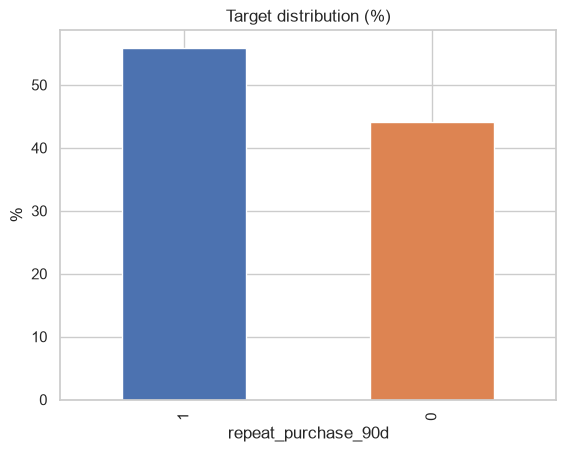

repeat_purchase_90d
1    0.559
0    0.441
Name: proportion, dtype: float64

In [5]:
ax = df_train[TARGET_COLUMN].value_counts(normalize=True).mul(100).plot(kind="bar", color=["#4C72B0", "#DD8452"])
ax.set_title("Target distribution (%)")
ax.set_ylabel("%")
plt.show()
df_train[TARGET_COLUMN].value_counts(normalize=True).round(3)

### Time coverage

Train: 2015-07-11 / 2025-02-15
Test : 2025-05-24 / 2026-10-06


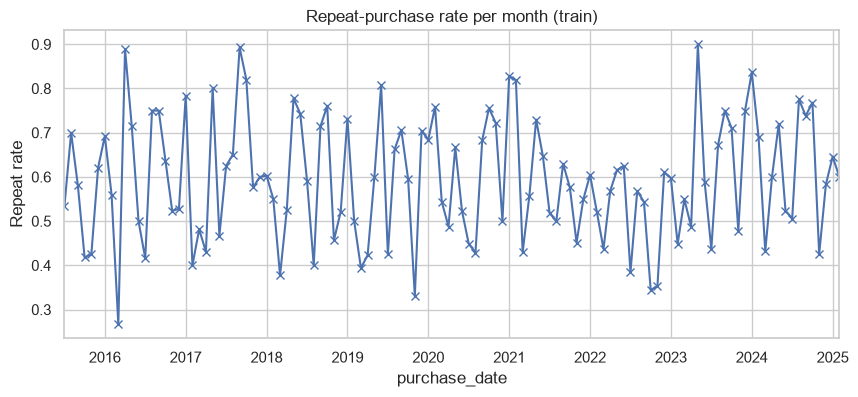

In [6]:
print("Train:", df_train["purchase_date"].min().date(), "/", df_train["purchase_date"].max().date())
print("Test :", df_test["purchase_date"].min().date(), "/", df_test["purchase_date"].max().date())

fig, ax = plt.subplots(figsize=(10, 4))
df_train.set_index("purchase_date").resample("ME")[TARGET_COLUMN].mean().plot(ax=ax, marker="x")
ax.set_title("Repeat-purchase rate per month (train)")
ax.set_ylabel("Repeat rate")
plt.show()

**Insight:** Test (2025-05 → 2026-10) comes entirely **after** train (2015 → 2025-02). A random K-fold would train on purchases that happen after the ones it's scored on, so  we validate with a **time-based split** instead.

### Customers

In [102]:
print("Unique customers in train:", df_train["customer_id"].nunique())
print("Rows per customer (train):")
print(df_train["customer_id"].value_counts().describe().round(1))
print(f"Test customers already seen in train: {df_test['customer_id'].isin(df_train['customer_id']).mean():.1%}")

Unique customers in train: 610
Rows per customer (train):
count    610.0
mean      10.7
std       20.0
min        1.0
25%        1.0
50%        4.0
75%       12.0
max      277.0
Name: count, dtype: float64
Test customers already seen in train: 94.5%


### Descriptive statistics

In [103]:
df_train.describe().T

,count,mean,min,25%,50%,75%,max,std
Total a Pagar,6469.0,925.556262,0.93,188.92,476.74,1087.67,22297.21,1334.997733
Total Bruto,6469.0,886.152705,0.83,175.74,445.74,1036.7,21578.28,1327.641086
Total Liquido,6469.0,773.336384,0.76,154.38,389.91,903.37,18127.81,1136.355723
Total Imp_,6469.0,152.219878,0.0,29.93,79.74,184.84,4169.4,225.262375
Total Portes,6469.0,1.151427,0.0,0.0,0.0,0.0,181.06,5.844091
Total Desc_ Global,6469.0,0.349907,0.0,0.0,0.0,0.0,218.49,5.116564
Total Desc_ Linha,6469.0,112.466414,0.0,0.0,13.13,92.28,4103.44,289.986307
Custo,6469.0,328.16504,0.0,49.05,152.54,396.061499,7427.400583,519.507218
N_ Detalhes,6469.0,21.524501,1.0,4.0,11.0,29.0,423.0,27.713419
invoice_count_current_purchase,6469.0,1.066007,1.0,1.0,1.0,1.0,5.0,0.310807


### Data quality: impossible / inconsistent values

In [104]:
checks = {
    "prior_mean_purchase_value >= 1e9 (placeholder)": (df_train["prior_mean_purchase_value"] >= 1e9).sum(),
    "spend_365d >= 1e9 (placeholder)": (df_train["spend_365d"] >= 1e9).sum(),
    "prior_mean_purchase_value < 0": (df_train["prior_mean_purchase_value"] < 0).sum(),
    "spend_365d < 0": (df_train["spend_365d"] < 0).sum(),
    "days_since_previous_purchase < 0": (df_train["days_since_previous_purchase"] < 0).sum(),
    "prior_mean_gap_days < 0": (df_train["prior_mean_gap_days"] < 0).sum(),
    "Custo > Total Liquido (sold below cost)": (df_train["Custo"] > df_train["Total Liquido"]).sum(),
    "prior_max < prior_min": (df_train["prior_max_purchase_value"] < df_train["prior_min_purchase_value"]).sum(),
    "count_90d > count_365d": (df_train["purchase_count_90d"] > df_train["purchase_count_365d"]).sum(),
    "spend_90d > spend_365d": (df_train["spend_90d"] > df_train["spend_365d"]).sum(),
    "prior_max_purchase_value > prior_total_spend": (df_train["prior_max_purchase_value"] > df_train["prior_total_spend"]).sum(),
}
pd.Series(checks, name="n_rows").to_frame()

,n_rows
prior_mean_purchase_value >= 1e9 (placeholder),16
spend_365d >= 1e9 (placeholder),15
prior_mean_purchase_value < 0,16
spend_365d < 0,15
days_since_previous_purchase < 0,16
prior_mean_gap_days < 0,16
Custo > Total Liquido (sold below cost),39
prior_max < prior_min,0
count_90d > count_365d,0
spend_90d > spend_365d,15


**Insight:** About 15–16 rows each contain impossible values: 1e9 placeholders, negative spend, negative day gaps, and `spend_90d > spend_365d`. A further 102 rows have `prior_max_purchase_value > prior_total_spend`, which should be impossible too. In Section 2 these get set to **NaN and imputed** rather than deleting the rows, since dropping them would lose otherwise valid purchases. Selling below cost (`Custo > Total Liquido`) can genuinely happen (for example promotions), so those rows **stay**.

### Missing values (train)

In [105]:
df_train.isna().sum()

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
repeat_purchase_90d                  0
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                           65
purchase_count_180d      

In [106]:
missing_pct = df_train.isna().mean() * 100
missing_pct.sort_values(ascending=False)

prior_std_gap_days                22.620141
prior_mean_gap_days               20.018365
prior_std_purchase_value          17.033976
prior_mean_purchase_value         13.192531
days_since_previous_purchase      13.177227
prior_max_purchase_value          10.223447
prior_min_purchase_value          10.223447
transport_method                   3.994490
warehouse                          3.979186
payment_type                       3.979186
spend_365d                         3.979186
salesperson                        3.963881
spend_90d                          0.994796
purchase_count_90d                 0.994796
purchase_date                      0.994796
purchase_count_180d                0.994796
spend_180d                         0.994796
document_series                    0.994796
spend_30d                          0.994796
commercial_zone                    0.994796
purchase_count_365d                0.994796
Total a Pagar                      0.994796
purchase_count_30d              

In [107]:
rows_multi_missing = (df_train.isna().sum(axis=1) > 1)

n_rows = rows_multi_missing.sum()
pct_rows = rows_multi_missing.mean() * 100

print(f"Rows with >1 missing value: {n_rows} ({pct_rows:.2f}%)")

Rows with >1 missing value: 1318 (20.17%)


In [108]:
# Are the prior_* gaps structural (first-time / single-purchase customers)?
prior_cols = ["days_since_previous_purchase", "prior_mean_purchase_value", "prior_std_purchase_value",
              "prior_min_purchase_value", "prior_max_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]

print(df_train.groupby(df_train["prior_purchase_count"].clip(upper=3))[prior_cols].apply(lambda d: d.isna().mean().round(2)))

df_train.assign(any_prior_missing=df_train[prior_cols].isna().any(axis=1)).groupby("any_prior_missing")[TARGET_COLUMN].mean()

                      days_since_previous_purchase  prior_mean_purchase_value  \
prior_purchase_count                                                            
0.0                                           1.00                       1.00   
1.0                                           0.04                       0.04   
2.0                                           0.05                       0.03   
3.0                                           0.03                       0.03   

                      prior_std_purchase_value  prior_min_purchase_value  \
prior_purchase_count                                                       
0.0                                        1.0                       1.0   
1.0                                        1.0                       0.0   
2.0                                        0.0                       0.0   
3.0                                        0.0                       0.0   

                      prior_max_purchase_value  prior_me

any_prior_missing
False    0.611754
True     0.436382
Name: repeat_purchase_90d, dtype: float64

**Insight:** Most columns are missing about 1% of their values at random, so a simple median or mode fill is enough.
The `prior_*` columns are missing 10 to 23%. Those gaps happen mostly when `prior_purchase_count` is 0 or 1, because there's no previous purchase to compute a gap or standard deviation from. They're **structural, not random**, and the repeat rate differs clearly between the two groups (**44%** for rows with gaps vs **61%** without). In Section 2 we'll fill them with 0 and add a `has_purchase_history` flag rather than plugging in the median.

### Categorical variables

warehouse            2
document_series      3
commercial_zone      5
payment_type         9
salesperson          9
transport_method    80
dtype: int64


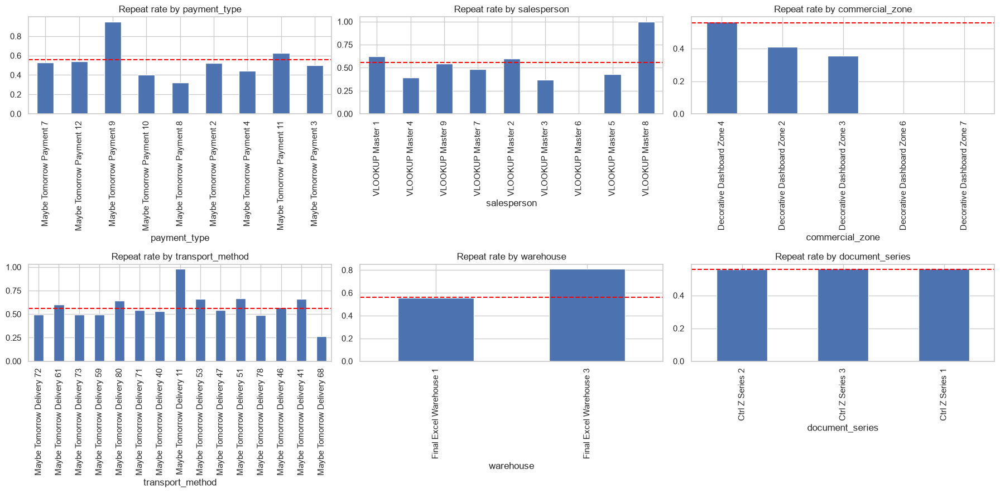

In [109]:
# Categorical variables: number of distinct values + repeat rate per category
cat_cols = ["payment_type", "salesperson", "commercial_zone", "transport_method", "warehouse", "document_series"]
print(df_train[cat_cols].nunique().sort_values())

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cat_cols):
    stats = df_train.groupby(col)[TARGET_COLUMN].agg(["mean", "count"]).sort_values("count", ascending=False).head(15)
    stats["mean"].plot(kind="bar", ax=ax)
    ax.axhline(df_train[TARGET_COLUMN].mean(), color="red", ls="--")
    ax.set_title(f"Repeat rate by {col}")
    ax.tick_params(axis="x", labelrotation=90)
plt.tight_layout()
plt.show()

In [110]:
# transport_method has high cardinality: how many categories are rare?
tm = df_train["transport_method"].value_counts()
print(f"{len(tm)} categories, {(tm < 30).sum()} with fewer than 30 rows")
print(f"Test categories not present in train: {set(df_test['transport_method'].dropna()) - set(tm.index)}")

80 categories, 51 with fewer than 30 rows
Test categories not present in train: {'Maybe Tomorrow Delivery 65', 'Maybe Tomorrow Delivery 54'}


### Identifier-like and noise columns

ID              corr with target: 0.012
customer_id     corr with target: -0.112
random_noise    corr with target: -0.012


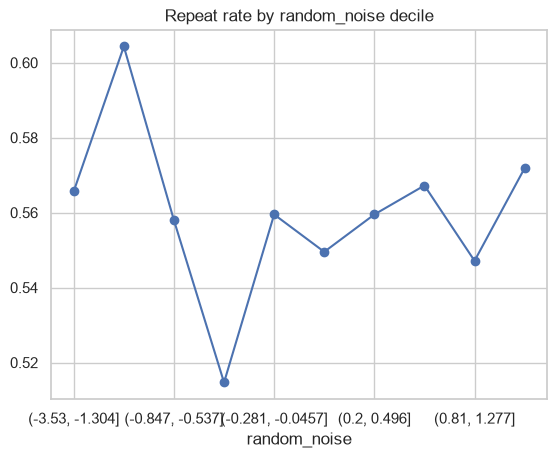

In [111]:
# Identifier-like and noise columns: do they carry any real signal?
for col in ["ID", "customer_id", "random_noise"]:
    print(f"{col:15s} corr with target: {df_train[col].corr(df_train[TARGET_COLUMN]):.3f}")

df_train.groupby(pd.qcut(df_train["random_noise"], 10), observed=False)[TARGET_COLUMN].mean().plot(marker="o", title="Repeat rate by random_noise decile")
plt.show()

**Insights:**
- `transport_method` has 80 categories, 51 of them with fewer than 30 rows, and 2 test categories never appear in train. We'll group the rare ones into "Other" before encoding, otherwise one-hot encoding would create very sparse columns.
- The other categoricals have few values (2 to 9), so we'll one-hot encode them.
- `random_noise` shows a flat repeat rate across its deciles, so it's pure noise. We'll **drop** it.
- `ID` and `customer_id` are identifiers. The small correlation `customer_id` shows is an artefact of how the numbers were assigned, not customer behaviour. We'll **drop** both from the features (and keep `ID` only for the submission).

### Univariate distributions

Total Desc_ Global                27.5
prior_max_purchase_value          21.3
spend_365d                        20.4
Total Portes                      19.5
prior_mean_purchase_value         18.8
prior_mean_gap_days                9.3
prior_std_gap_days                 7.8
days_since_previous_purchase       6.5
invoice_count_current_purchase     6.4
Total Desc_ Linha                  5.9
prior_min_purchase_value           5.9
spend_30d                          5.5
Total Imp_                         4.8
Custo                              4.6
Total Bruto                        4.3
dtype: float64


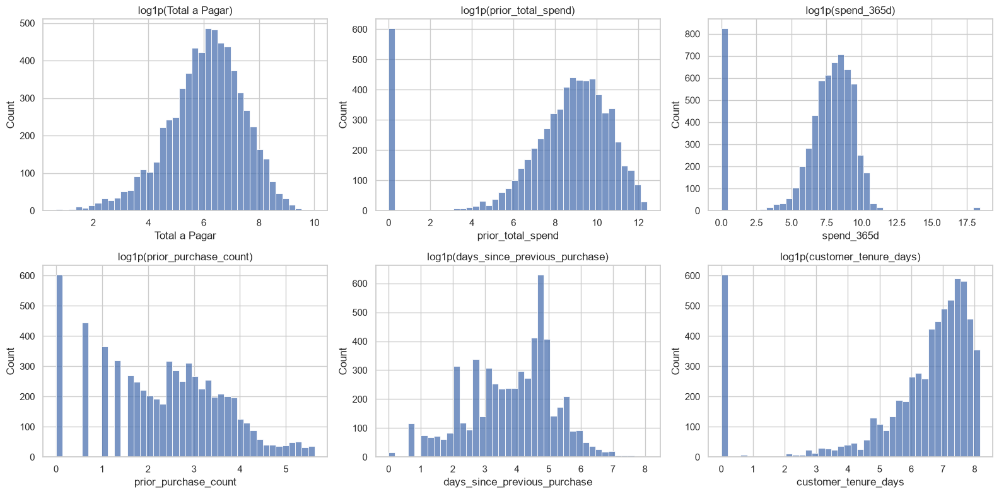

In [112]:
# Univariate: monetary/count variables are heavily right-skewed
num_cols = df_train.select_dtypes("number").columns.drop([TARGET_COLUMN, "ID", "customer_id", "random_noise"])
print(df_train[num_cols].skew().sort_values(ascending=False).round(1).head(15))

show = ["Total a Pagar", "prior_total_spend", "spend_365d", "prior_purchase_count", "days_since_previous_purchase", "customer_tenure_days"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), show):
    sns.histplot(np.log1p(df_train[col].clip(lower=0, upper=1e8)), ax=ax, bins=40)
    ax.set_title(f"log1p({col})")
plt.tight_layout()
plt.show()

### Multivariate relationships

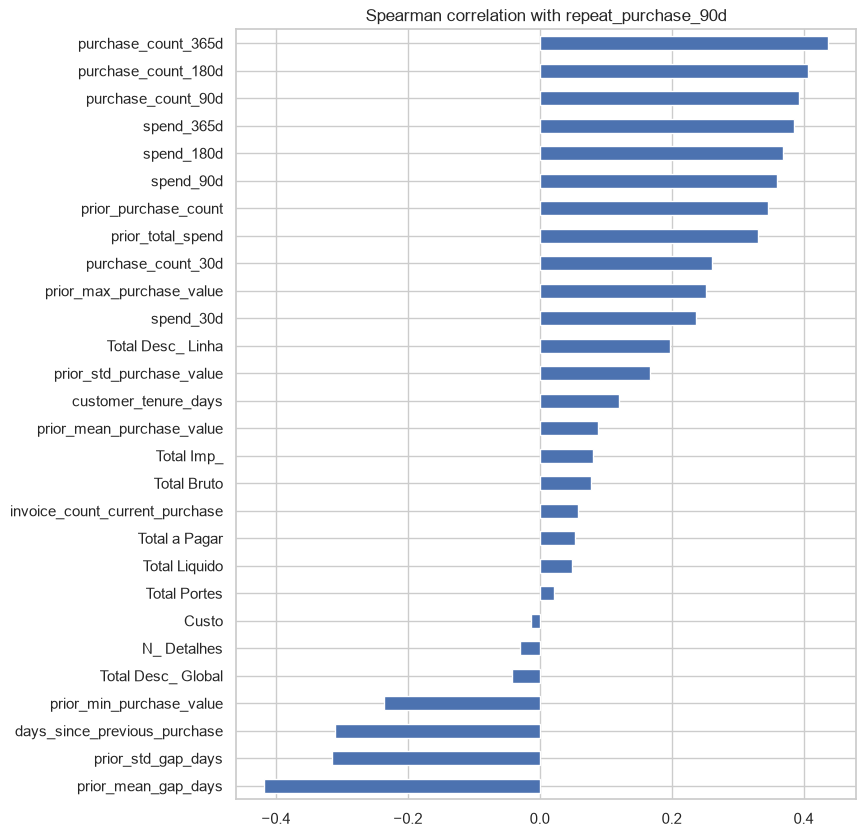

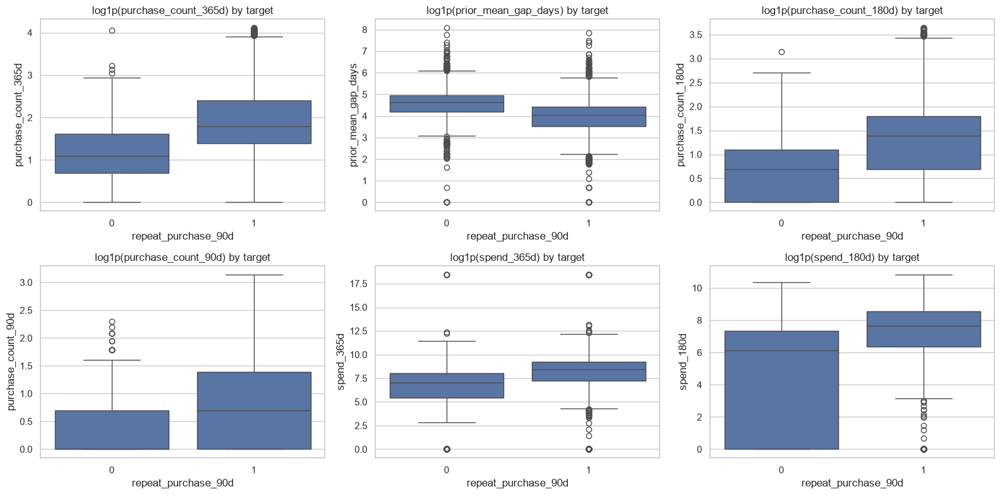

In [113]:
# Multivariate: relationship with the target
corr_target = df_train[num_cols].corrwith(df_train[TARGET_COLUMN], method="spearman").sort_values()
corr_target.plot(kind="barh", figsize=(8, 10), title="Spearman correlation with repeat_purchase_90d")
plt.show()

top = corr_target.abs().sort_values(ascending=False).head(6).index
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), top):
    sns.boxplot(data=df_train, x=TARGET_COLUMN, y=np.log1p(df_train[col].clip(lower=0, upper=1e8)), ax=ax)
    ax.set_title(f"log1p({col}) by target")
plt.tight_layout()
plt.show()

In [114]:
# Multicollinearity: highly correlated feature pairs (|rho| > 0.9)
corr = df_train[num_cols].corr(method="spearman")
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.9].sort_values(ascending=False)

Total a Pagar             Total Liquido               0.999547
Total Bruto               Total Liquido               0.991385
Total a Pagar             Total Bruto                 0.990854
purchase_count_30d        spend_30d                   0.965454
prior_std_purchase_value  prior_max_purchase_value    0.922818
purchase_count_90d        spend_90d                   0.909204
prior_purchase_count      prior_total_spend           0.903270
dtype: float64

**Insights:**
- The monetary and count variables are strongly right-skewed. We'll apply `log1p` before scaling for linear models, and cap the extreme values instead of deleting rows.
- The strongest predictors are **purchase frequency** (`purchase_count_365d/180d/90d`, `prior_purchase_count`, around 0.3) and **gap length** (`prior_mean_gap_days`, `days_since_previous_purchase`, which are negative). Customers who buy often and recently come back.
- The current purchase's value (`Total *`) carries little signal.
- Some pairs are almost duplicates (ρ > 0.9): `Total Bruto`/`Liquido`/`a Pagar`, the count and spend of the same window (30d, 90d), and `prior_purchase_count`/`prior_total_spend`. Feature selection in Section 3 will keep only one of each group.

### Customer table (clientes.csv)

In [115]:
df_clientes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          1143 non-null   int64  
 1   country_or_region    1143 non-null   object 
 2   commercial_region    1029 non-null   object 
 3   island               565 non-null    object 
 4   municipality         984 non-null    object 
 5   city                 597 non-null    object 
 6   postal_area          1072 non-null   object 
 7   postal_code          973 non-null    object 
 8   street               545 non-null    object 
 9   address              1137 non-null   object 
 10  customer_type        0 non-null      float64
 11  company_name         1143 non-null   object 
 12  customer_since_year  1143 non-null   int64  
dtypes: float64(1), int64(2), object(10)
memory usage: 116.2+ KB


In [116]:
df_clientes.head(10)

,customer_id,country_or_region,commercial_region,island,municipality,city,postal_area,postal_code,street,address,customer_type,company_name,customer_since_year
0,842570,Country CT11: Land of The Final Version,Region RG37: We Will See Later,NaN,NaN,City CY417: Missing Cell Port,NaN,Postal code PC828: #REF! Delivery Route,NaN,Address AD1120: Cell Without a Home,NaN,Excel Is Not A Database Ltd 150,2018
1,770941,Country CT9: Land of The Final Version,NaN,NaN,NaN,NaN,NaN,Postal code PC56: #REF! Delivery Route,NaN,Address AD62: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1064,2021
2,827053,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC827: #REF! Delivery Route,Street ST170: PowerPoint New Walk,Address AD449: Cell Without a Home,NaN,Excel Is Not A Database Ltd 113,2016
3,494648,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD454: Cell Without a Home,NaN,Excel Is Not A Database Ltd 430,2015
4,429291,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC826: #REF! Delivery Route,NaN,Address AD453: Cell Without a Home,NaN,Excel Is Not A Database Ltd 673,2015
5,344764,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,City CY171: VLOOKUP Grove,Postal area PA271: Hidden Sheet Sector,Postal code PC825: #REF! Delivery Route,Street ST167: Spill Error Way,Address AD445: Cell Without a Home,NaN,Excel Is Not A Database Ltd 126,2015
6,774295,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,City CY171: VLOOKUP Grove,Postal area PA271: Hidden Sheet Sector,Postal code PC825: #REF! Delivery Route,Street ST167: Spill Error Way,Address AD444: Cell Without a Home,NaN,Excel Is Not A Database Ltd 125,2022
7,383741,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,City CY171: VLOOKUP Grove,Postal area PA271: Hidden Sheet Sector,Postal code PC824: #REF! Delivery Route,Street ST169: Where-less Query Walk,Address AD443: Cell Without a Home,NaN,Excel Is Not A Database Ltd 476,2015
8,709384,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,City CY171: VLOOKUP Grove,Postal area PA271: Hidden Sheet Sector,Postal code PC824: #REF! Delivery Route,Street ST169: Where-less Query Walk,Address AD448: Cell Without a Home,NaN,Excel Is Not A Database Ltd 1074,2015
9,240646,Country CT10: Land of The Final Version,Region RG17: We Will See Later,Island IS2: The Pivot Archipelago,Municipality MU14: Council of Last Minute Edits,NaN,Postal area PA271: Hidden Sheet Sector,Postal code PC823: #REF! Delivery Route,Street ST168: Last Save Way,Address AD447: Cell Without a Home,NaN,Excel Is Not A Database Ltd 837,2015


In [117]:
df_clientes.isna().sum()

customer_id               0
country_or_region         0
commercial_region       114
island                  578
municipality            159
city                    546
postal_area              71
postal_code             170
street                  598
address                   6
customer_type          1143
company_name              0
customer_since_year       0
dtype: int64

In [118]:
missing_pct = df_clientes.isna().mean() * 100
missing_pct.sort_values(ascending=False)

customer_type          100.000000
street                  52.318460
island                  50.568679
city                    47.769029
postal_code             14.873141
municipality            13.910761
commercial_region        9.973753
postal_area              6.211724
address                  0.524934
customer_id              0.000000
country_or_region        0.000000
company_name             0.000000
customer_since_year      0.000000
dtype: float64

In [119]:
rows_multi_missing = (df_clientes.isna().sum(axis=1) > 1)

n_rows = rows_multi_missing.sum()
pct_rows = rows_multi_missing.mean() * 100

print(f"Rows with >1 missing value: {n_rows} ({pct_rows:.2f}%)")

Rows with >1 missing value: 1022 (89.41%)


In [120]:
df_clientes.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,1143.0,NaN,NaN,NaN,553917.786527,259693.430653,103940.0,323855.5,555330.0,782527.5,998870.0
country_or_region,1143,11,Country CT10: Land of The Final Version,1079,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commercial_region,1029,37,Region RG17: We Will See Later,519,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,565,10,Island IS7: The Pivot Archipelago,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN
municipality,984,183,Municipality MU1: Council of Last Minute Edits,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,597,417,City CY194: PowerPoint New Hills,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
postal_area,1072,271,Postal area PA259: Hidden Sheet Sector,57,NaN,NaN,NaN,NaN,NaN,NaN,NaN
postal_code,973,828,Postal code PC545: #REF! Delivery Route,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street,545,511,Street ST192: Last Save Walk,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
address,1137,1120,Address AD489: Cell Without a Home,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [121]:
# Which clientes columns could be useful features?
summary = pd.DataFrame({
    "missing_%": df_clientes.isna().mean().mul(100).round(1),
    "n_unique": df_clientes.nunique(),
    "unique_ratio": (df_clientes.nunique() / len(df_clientes)).round(2),
}).sort_values("unique_ratio", ascending=False)
summary

,missing_%,n_unique,unique_ratio
customer_id,0.0,1143,1.00
company_name,0.0,1141,1.00
address,0.5,1120,0.98
postal_code,14.9,828,0.72
street,52.3,511,0.45
city,47.8,417,0.36
postal_area,6.2,271,0.24
municipality,13.9,183,0.16
commercial_region,10.0,37,0.03
country_or_region,0.0,11,0.01


**Insight:** Several `clientes` columns can't be used directly:
- `customer_type` is 100% empty.
- `company_name`, `address`, `street` and `postal_code` are close to unique per customer, so they act like identifiers and would let the model memorise customers.
- `city`, `island` and `street` are about 50% empty.

We'll keep only the lower-cardinality columns: `country_or_region`, `commercial_region` and `customer_since_year`.

Train rows without a match in clientes: 0


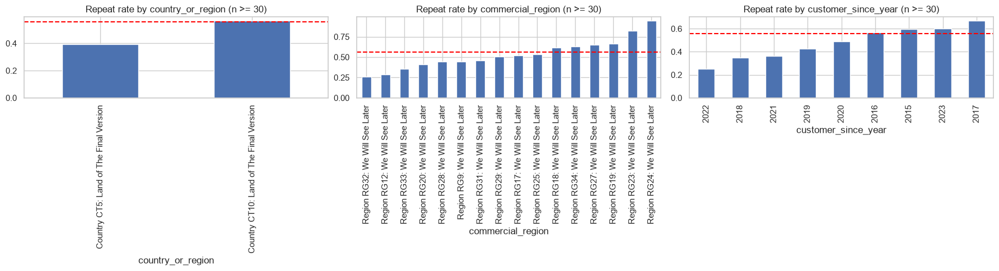

In [122]:
df_merged = df_train.merge(
    df_clientes[["customer_id", "country_or_region", "commercial_region", "customer_since_year"]],
    on="customer_id", how="left",
)
print("Train rows without a match in clientes:", df_merged["country_or_region"].isna().sum())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["country_or_region", "commercial_region", "customer_since_year"]):
    stats = df_merged.groupby(col)[TARGET_COLUMN].agg(["mean", "count"])
    stats = stats[stats["count"] >= 30].sort_values("mean")
    stats["mean"].plot(kind="bar", ax=ax)
    ax.axhline(df_merged[TARGET_COLUMN].mean(), color="red", ls="--")
    ax.set_title(f"Repeat rate by {col} (n >= 30)")
    ax.tick_params(axis="x", labelrotation=90)
plt.tight_layout()
plt.show()

**Insight:** If the repeat rate clearly differs by region or by `customer_since_year`, we merge these columns in Section 2. If the bars sit flat around the average line, `clientes` adds nothing useful and we leave it out.

### Determining of Postal-code would be a good predictor for a repeted purchase

**Line of Thought:** Since in most business situations, postal-codes can be used as a predictor for repetead purchases, in this situation we are trying to do the same 

In [123]:
geo_cols = ["postal_code", "postal_area", "municipality", "island", "commercial_region", "country_or_region"]

df_geo = df_train.merge(df_clientes[["customer_id"] + geo_cols], on="customer_id", how="left")
df_geo_test = df_test.merge(df_clientes[["customer_id"] + geo_cols], on="customer_id", how="left")

rows = []
for col in geo_cols:
    cust_per_code = df_geo.groupby(col)["customer_id"].nunique()
    rows_per_code = df_geo[col].value_counts()
    rows.append({
        "column": col,
        "n_codes_train": cust_per_code.size,
        "missing_%": round(df_geo[col].isna().mean() * 100, 1),
        "% postal-codes with 1 customer": round((cust_per_code == 1).mean() * 100, 1),
        "median customers/code": cust_per_code.median(),
        "% postal-codes with < 30 rows": round((rows_per_code < 30).mean() * 100, 1),
        "% test rows with code unseen in train": round(
            (~df_geo_test[col].dropna().isin(df_geo[col].dropna())).mean() * 100, 1),
    })
geo_summary = pd.DataFrame(rows).set_index("column")
geo_summary

,n_codes_train,missing_%,% postal-codes with 1 customer,median customers/code,% postal-codes with < 30 rows,% test rows with code unseen in train
column,,,,,,
postal_code,519,3.4,89.0,1.0,88.8,4.2
postal_area,189,4.3,57.7,1.0,77.2,1.2
municipality,150,3.3,44.7,2.0,76.0,0.7
island,10,33.8,10.0,25.5,10.0,0.0
commercial_region,32,0.5,28.1,7.0,50.0,0.0
country_or_region,7,0.0,42.9,2.0,71.4,0.0


**Insight:**  89% of postal codes belong to one customer, so the variable acts as a customer identifier, and 4% of test rows have a code never seen in train.

**Decision:** drop `postal_code`, `postal_area` and `municipality`. Keep `commercial_region` (and test `island` / `country_or_region`, which show weaker effects) in Section 2.

## 2. Clean and pre-process the data

**Libraries**

In [124]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RANDOM_STATE = 42

In [125]:
NON_NEGATIVE_COLS = ["prior_mean_purchase_value", "spend_365d", "days_since_previous_purchase", "prior_mean_gap_days"]

def clean_anomalies(df):
    df = df.copy()
    # 1e9 is a placeholder, not a real amount
    cols = ["prior_mean_purchase_value", "spend_365d"]
    df[cols] = df[cols].mask(df[cols] >= 1e9)
    # Spend and day gaps cannot be negative
    for col in NON_NEGATIVE_COLS:
        df.loc[df[col] < 0, col] = np.nan
    # A 365-day window must contain the 90-day window
    df.loc[df["spend_90d"] > df["spend_365d"], "spend_365d"] = np.nan
    # The largest previous purchase cannot exceed the total of all previous purchases
    df.loc[df["prior_max_purchase_value"] > df["prior_total_spend"], "prior_max_purchase_value"] = np.nan
    return df

check_cols = NON_NEGATIVE_COLS + ["prior_max_purchase_value"]
print("NaN before cleaning:", df_train[check_cols].isna().sum().sum())
print("NaN after cleaning: ", clean_anomalies(df_train)[check_cols].isna().sum().sum())

NaN before cleaning: 3959
NaN after cleaning:  4169


**Decision:** Impossible values (the 1e9 placeholders, negative spend or day gaps, and window totals that contradict each other) are set to **NaN** and imputed later, instead of deleting the rows, so the rest of each purchase is kept. These are fixed rules that learn nothing from the data, so applying them to test causes no leakage. Sales below cost are plausible (promotions), so they stay.

In [126]:
CLIENT_COLS = ["customer_id", "country_or_region", "commercial_region"]

def add_client_info(df):
    return df.merge(df_clientes[CLIENT_COLS], on="customer_id", how="left", validate="many_to_one")

**Decision:** `clientes` is merged with a left join on `customer_id`. `validate="many_to_one"` guarantees no row is duplicated. Only `country_or_region` and `commercial_region` are kept: they have few categories and a real signal above the shuffled baseline. `postal_code`, `address`, `company_name` and `street` are identifier-like, and `customer_type` is empty. `customer_since_year` overlaps with `customer_tenure_days`, which is already in train.

In [127]:
def safe_div(a, b):
    return np.where(b > 0, a / b.where(b > 0), np.nan)

def add_features(df):
    df = df.copy()

    # Structural missing values: no purchase history -> no previous spend
    no_history = df["prior_purchase_count"] == 0
    df["has_purchase_history"] = (~no_history).astype(int)
    for col in ["prior_mean_purchase_value", "prior_min_purchase_value", "prior_max_purchase_value"]:
        df.loc[no_history & df[col].isna(), col] = 0
    # With 0-1 purchases (or 0-2 for gaps) a standard deviation is undefined -> 0 variability
    df.loc[(df["prior_purchase_count"] <= 1) & df["prior_std_purchase_value"].isna(), "prior_std_purchase_value"] = 0
    df.loc[(df["prior_purchase_count"] <= 2) & df["prior_std_gap_days"].isna(), "prior_std_gap_days"] = 0
    # Day gaps stay NaN -> median + missing indicator in the pipeline

    # Date features (the raw date is dropped: the test years never appear in train)
    df["purchase_month"] = df["purchase_date"].dt.month
    df["purchase_dayofweek"] = df["purchase_date"].dt.dayofweek

    # Current purchase
    df["margin"] = df["Total Liquido"] - df["Custo"]
    df["margin_rate"] = safe_div(df["margin"], df["Total Liquido"])
    df["discount_rate"] = safe_div(df["Total Desc_ Linha"], df["Total Bruto"])

    # Customer behaviour
    df["activity_trend_90_365"] = safe_div(df["purchase_count_90d"], df["purchase_count_365d"])
    df["recency_vs_usual_gap"] = safe_div(df["days_since_previous_purchase"], df["prior_mean_gap_days"])
    df["avg_ticket_365d"] = safe_div(df["spend_365d"], df["purchase_count_365d"])
    df["purchases_per_year"] = safe_div(df["prior_purchase_count"], df["customer_tenure_days"] / 365)
    return df

**Decision (missing values):** The `prior_*` gaps are **structural** (Section 1): a customer with no previous purchases has no previous spend, so 0 is the true value, not an estimate. The gaps in the day-gap columns stay NaN and get median imputation plus a **missing indicator**, because "first purchase" is itself informative (44% vs 61% repeat rate).

**New features:**
| Feature | Why |
|---|---|
| `has_purchase_history` | First-time buyers behave differently |
| `activity_trend_90_365` | Is the customer speeding up or slowing down? |
| `recency_vs_usual_gap` | Is the customer later than usual? (above 1 = overdue) |
| `purchases_per_year` | Purchase frequency, independent of how long they've been a customer |
| `avg_ticket_365d` | Typical basket size |
| `margin`, `margin_rate`, `discount_rate` | Profitability and promotion intensity of the current purchase |
| `purchase_month`, `purchase_dayofweek` | Seasonality (the raw date is dropped because the test years never occur in train) |

Divisions by zero return NaN instead of infinity.

In [128]:

def reconstruct_historical_features(df, history):
    """
    Recover historical features using only earlier purchases.
    Only reconstruct rows with a verified complete history.
    """
    result = df.copy()

    purchases = history[
        ["customer_id", "purchase_date", "Total a Pagar"]
    ].copy()

    purchases["purchase_date"] = pd.to_datetime(
        purchases["purchase_date"], errors="coerce"
    )
    purchases["Total a Pagar"] = pd.to_numeric(
        purchases["Total a Pagar"], errors="coerce"
    )

    purchases = purchases.dropna(
        subset=["customer_id", "purchase_date"]
    ).sort_values(["customer_id", "purchase_date"])

    # Organize transactions by customer.
    customer_histories = {
        customer_id: customer_purchases
        for customer_id, customer_purchases
        in purchases.groupby("customer_id")
    }

    changes = []
    verified_rows = 0

    def correct_value(row_index, column, expected, check_difference=False):
        original = result.at[row_index, column]

        needs_correction = pd.isna(original)

        if check_difference and pd.notna(original):
            needs_correction = not np.isclose(
                original, expected, atol=0.01, rtol=0
            )

        if needs_correction:
            result.at[row_index, column] = expected

            changes.append({
                "row_index": row_index,
                "feature": column,
                "old_value": original,
                "new_value": expected
            })

    for index, row in result.iterrows():
        customer_id = row["customer_id"]
        purchase_date = row["purchase_date"]

        if pd.isna(customer_id) or pd.isna(purchase_date):
            continue

        if customer_id not in customer_histories:
            continue

        customer_purchases = customer_histories[customer_id]

        # The current purchase and future purchases are excluded.
        previous = customer_purchases.loc[
            customer_purchases["purchase_date"] < purchase_date
        ]

        # Check whether all previous purchases are observable.
        reported_count = row["prior_purchase_count"]

        if pd.isna(reported_count) or len(previous) != reported_count:
            continue

        verified_rows += 1

        dates = previous["purchase_date"]
        amounts = previous["Total a Pagar"]

        valid_amounts = (
            amounts.notna().all()
            and np.isfinite(amounts).all()
            and amounts.ge(0).all()
        )

        # Features requiring at least one previous purchase.
        if len(previous) >= 1:
            days_since_last = (purchase_date - dates.iloc[-1]).days

            correct_value(
                index, "days_since_previous_purchase", days_since_last
            )

            if valid_amounts:
                correct_value(
                    index, "prior_mean_purchase_value", amounts.mean()
                )
                correct_value(
                    index, "prior_min_purchase_value", amounts.min()
                )
                correct_value(
                    index, "prior_total_spend", amounts.sum()
                )

                expected_max = amounts.max()
                original_max = result.at[index, "prior_max_purchase_value"]

                # Correct missing or inflated historical maximums.
                if pd.isna(original_max) or original_max > expected_max + 0.01:
                    correct_value(
                        index, "prior_max_purchase_value",
                        expected_max, check_difference=True
                    )

        # Features requiring at least two previous purchases.
        if len(previous) >= 2:
            gaps = dates.diff().dropna().dt.days

            correct_value(
                index, "prior_mean_gap_days", gaps.mean()
            )

            if valid_amounts:
                correct_value(
                    index, "prior_std_purchase_value",
                    amounts.std(ddof=1)
                )

        # Gap standard deviation requires at least three purchases.
        if len(previous) >= 3:
            correct_value(
                index, "prior_std_gap_days", gaps.std(ddof=1)
            )

        # Reconstruct historical purchase counts and spending windows.
        for window_days in [30, 90, 180, 365]:
            window_start = purchase_date - pd.Timedelta(days=window_days)

            window = previous.loc[
                previous["purchase_date"] >= window_start
            ]

            count_column = f"purchase_count_{window_days}d"
            spend_column = f"spend_{window_days}d"

            reported_window_count = result.at[index, count_column]

            if pd.isna(reported_window_count):
                correct_value(index, count_column, len(window))
                reported_window_count = len(window)

            # Do not reconstruct spending if the window count disagrees.
            if reported_window_count != len(window):
                continue

            window_amounts = window["Total a Pagar"]

            if (
                window_amounts.notna().all()
                and np.isfinite(window_amounts).all()
                and window_amounts.ge(0).all()
            ):
                correct_value(
                    index,
                    spend_column,
                    window_amounts.sum(),
                    check_difference=(window_days == 365)
                )

    audit = pd.DataFrame(
        changes,
        columns=["row_index", "feature", "old_value", "new_value"]
    )

    print(f"Verified histories: {verified_rows}/{len(result)}")
    print(f"Corrections made: {len(audit)}")

    if not audit.empty:
        display(audit["feature"].value_counts().to_frame("corrections"))

    return result, audit


In [129]:

DROP_COLS = ["ID", "customer_id", "random_noise", "purchase_date"]


def prepare(df, history):
    # 1. Remove artificial and impossible values.
    cleaned = clean_anomalies(df)

    # 2. Recover historical values when the history is verifiable.
    recovered, audit = reconstruct_historical_features(
        cleaned, history
    )

    # 3. Add customer information.
    with_customer_info = add_client_info(recovered)

    # 4. Create engineered features using corrected historical data.
    prepared = add_features(with_customer_info)

    # 5. Remove identifiers and the target.
    X = prepared.drop(
        columns=DROP_COLS + [TARGET_COLUMN],
        errors="ignore"
    )

    return X, audit


# Reconstruct training rows using the training transactions.
X_full, train_audit = prepare(
    df_train,
    history=df_train
)

y_full = df_train[TARGET_COLUMN]


# Test rows may use earlier transactions from train and test.
full_history = pd.concat(
    [df_train, df_test],
    ignore_index=True
)

X_test, test_audit = prepare(
    df_test,
    history=full_history
)

test_ids = df_test["ID"]

assert X_full.index.equals(df_train.index)
assert X_test.index.equals(df_test.index)

print("Training shape:", X_full.shape)
print("Test shape:", X_test.shape)


Verified histories: 5340/6534
Corrections made: 858


,corrections
feature,
spend_365d,225
prior_mean_gap_days,178
prior_mean_purchase_value,176
days_since_previous_purchase,174
prior_max_purchase_value,105


Verified histories: 289/986
Corrections made: 54


,corrections
feature,
spend_365d,16
days_since_previous_purchase,12
prior_mean_gap_days,10
prior_mean_purchase_value,9
prior_max_purchase_value,7


Training shape: (6534, 46)
Test shape: (986, 46)


In [130]:
display(train_audit.head(20))
display(test_audit.head(20))

,row_index,feature,old_value,new_value
0,6,spend_365d,NaN,7472.490000
1,8,spend_365d,53906.674517,3195.420000
2,24,prior_mean_gap_days,NaN,35.800000
3,40,spend_365d,NaN,351.340000
4,42,prior_max_purchase_value,NaN,1680.680000
5,43,prior_mean_purchase_value,NaN,1066.061167
6,50,days_since_previous_purchase,NaN,140.000000
7,58,spend_365d,11536.764996,712.490000
8,65,prior_mean_gap_days,NaN,150.500000
9,67,prior_mean_purchase_value,NaN,659.242857


,row_index,feature,old_value,new_value
0,4,days_since_previous_purchase,NaN,78.000000
1,6,spend_365d,NaN,546.280000
2,26,prior_mean_purchase_value,NaN,386.481667
3,55,prior_mean_gap_days,NaN,62.555556
4,84,days_since_previous_purchase,NaN,337.000000
5,108,days_since_previous_purchase,NaN,724.000000
6,166,spend_365d,NaN,165.850000
7,178,prior_mean_purchase_value,NaN,503.960000
8,197,prior_mean_purchase_value,NaN,1619.562222
9,207,spend_365d,4801.104679,404.670000


**Decision:** `ID` and `customer_id` are identifiers, `random_noise` has no relationship with the target (Section 1), and `purchase_date` is replaced by the month and day-of-week features. `ID` is stored separately so the submission keeps it unchanged.

In [131]:
CAT_COLS = ["payment_type", "salesperson", "commercial_zone", "transport_method", "warehouse",
            "document_series", "country_or_region", "commercial_region"]

# Ratios, rates and small bounded numbers: no log transform
PLAIN_NUM_COLS = ["margin_rate", "discount_rate", "activity_trend_90_365", "recency_vs_usual_gap",
                  "purchase_month", "purchase_dayofweek", "has_purchase_history",
                  "invoice_count_current_purchase", "margin"]   # margin can be negative -> no log

# Everything else numeric is monetary / count / days -> right-skewed
SKEWED_NUM_COLS = [c for c in X_full.select_dtypes("number").columns if c not in PLAIN_NUM_COLS]

assert set(CAT_COLS + PLAIN_NUM_COLS + SKEWED_NUM_COLS) == set(X_full.columns)

In [132]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Caps values at the percentiles learned in fit() (training data only)."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower, self.upper = lower, upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, self.lower, axis=0)
        self.high_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


def build_preprocessor(scale=True):
    """scale=True for linear/distance models (logistic regression, KNN); False for tree models."""
    scaler = [("scale", StandardScaler())] if scale else []

    skewed = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("clip", QuantileClipper(0.01, 0.99)),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        *scaler,
    ])
    plain = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("clip", QuantileClipper(0.01, 0.99)),
        *scaler,
    ])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
        # Categories with < 30 training rows, or unseen in train, go into one "infrequent" column
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False)),
    ])
    return ColumnTransformer([
        ("skewed", skewed, SKEWED_NUM_COLS),
        ("plain", plain, PLAIN_NUM_COLS),
        ("cat", categorical, CAT_COLS),
    ], verbose_feature_names_out=False)

**Decisions:**
- **Imputation:** the median for numbers, because it's robust to the skew; "Unknown" for categories. `add_indicator=True` keeps the information that a value was missing.
- **Outliers:** values are capped at the 1st and 99th percentiles **learned on the training data**, instead of deleting rows. Extreme spenders are real customers.
- **Skew:** `log1p` on monetary, count and day columns (skewness up to 30). It's applied after capping and before scaling, because scaling creates negative values that the log cannot handle, and `log1p` keeps the zeros valid.
- **Categoricals:** one-hot encoding. The 80 values of `transport_method` (51 of them with fewer than 30 rows) and any unseen test categories are grouped automatically into one "infrequent" column.
- **Scaling:** `StandardScaler` for logistic regression and KNN, which are sensitive to feature scale. Tree models split on thresholds, so `build_preprocessor(scale=False)` skips scaling for them.
- **Reproducibility and no leakage:** every step that learns something (medians, percentiles, categories, mean and standard deviation) sits inside one `Pipeline` that is **fitted on the training data only**. Test data is only ever transformed.

In [133]:

from sklearn.model_selection import TimeSeriesSplit

dates = pd.to_datetime(df_train["purchase_date"])

# Find the next purchase date for each customer.
# Duplicate purchases on the same date count as one purchase date.
purchase_days = (
    df_train[["customer_id", "purchase_date"]]
    .dropna()
    .drop_duplicates()
    .sort_values(["customer_id", "purchase_date"])
    .copy()
)

purchase_days["next_purchase_date"] = (
    purchase_days.groupby("customer_id")["purchase_date"].shift(-1)
)

# Match the next purchase date back to every original row.
next_purchase_dates = df_train[
    ["customer_id", "purchase_date"]
].merge(
    purchase_days,
    on=["customer_id", "purchase_date"],
    how="left",
    sort=False,
    validate="many_to_one"
)["next_purchase_date"]

next_purchase_dates.index = df_train.index



def labels_known_before(cutoff, row_dates, labels, next_dates):
    """
    Keep purchases whose target was known before the cutoff.
    """

    # Any label is known after its full 90-day period.
    completed_horizon = (
        row_dates + pd.Timedelta(days=90) < cutoff
    )

    # A positive label is also known as soon as a repeat purchase occurs.
    confirmed_positive = (
        labels.eq(1)
        & next_dates.gt(row_dates)
        & next_dates.lt(cutoff)
        & next_dates.le(row_dates + pd.Timedelta(days=90))
    )

    # Only purchases before the cutoff can enter training.
    return (
        row_dates.lt(cutoff)
        & (completed_horizon | confirmed_positive)
    )



# Simulate training the model on January 1, 2024.
validation_start = pd.Timestamp("2024-01-01")
validation_end = pd.Timestamp("2025-01-01")

train_mask = labels_known_before(
    validation_start,
    dates,
    y_full,
    next_purchase_dates
)

validation_mask = (
    dates.ge(validation_start)
    & dates.lt(validation_end)
)

train_idx = df_train.index[train_mask]
valid_idx = df_train.index[validation_mask]

X_tr = X_full.loc[train_idx]
y_tr = y_full.loc[train_idx]

X_val = X_full.loc[valid_idx]
y_val = y_full.loc[valid_idx]


# Check the final temporal split.
recent_period = (
    dates.ge(validation_start - pd.Timedelta(days=90))
    & dates.lt(validation_start)
)

print("TRAINING:", len(train_idx), "rows")
print("VALIDATION:", len(valid_idx), "rows")

print(
    "Recent confirmed positives retained:",
    (train_mask & recent_period & y_full.eq(1)).sum()
)

print(
    "Recent negatives retained:",
    (train_mask & recent_period & y_full.eq(0)).sum()
)

print(
    "Validation period:",
    dates.loc[valid_idx].min(),
    "to",
    dates.loc[valid_idx].max()
)

assert dates.loc[train_idx].lt(validation_start).all()
assert dates.loc[valid_idx].ge(validation_start).all()


# Fit preprocessing only with training rows.
preprocessor = build_preprocessor(scale=True)

X_tr_t = preprocessor.fit_transform(X_tr)
X_val_t = preprocessor.transform(X_val)

feature_names = preprocessor.get_feature_names_out()

print("Features after preprocessing:", len(feature_names))
print("NaN left:", np.isnan(X_tr_t).sum(), np.isnan(X_val_t).sum())


TRAINING: 5497 rows
VALIDATION: 757 rows
Recent confirmed positives retained: 94
Recent negatives retained: 0
Validation period: 2024-01-01 00:00:00 to 2024-12-31 00:00:00
Features after preprocessing: 117
NaN left: 0 0


In [134]:
X_tr_df = pd.DataFrame(X_tr_t, columns=feature_names, index=X_tr.index)

skew_check = pd.DataFrame({
    "skew_before": X_tr[SKEWED_NUM_COLS].skew(),
    "skew_after": X_tr_df[SKEWED_NUM_COLS].skew(),
}).round(2).sort_values("skew_before", ascending=False)
display(skew_check.head(10))

# For the submission: refit on ALL of train, then only transform test
final_preprocessor = build_preprocessor(scale=True).fit(X_full)
X_test_t = final_preprocessor.transform(X_test)
print("Test matrix:", X_test_t.shape, "| NaN:", np.isnan(X_test_t).sum())

,skew_before,skew_after
Total Desc_ Global,28.72,8.48
spend_365d,27.01,-1.40
prior_mean_purchase_value,24.96,-1.91
Total Portes,19.73,1.86
avg_ticket_365d,18.58,-0.41
purchases_per_year,9.59,1.06
prior_mean_gap_days,7.84,-0.65
Total Desc_ Linha,6.66,0.30
prior_min_purchase_value,6.23,-0.30
days_since_previous_purchase,5.15,-0.39


Test matrix: (986, 154) | NaN: 0


## 3. Feature selection

**Strategy (in order):**

1. **Filter: variance.** Drop constant or near-constant features.
2. **Filter: redundancy.** For each pair of features with Spearman correlation above 0.9, keep the one more related to the target.
3. **Filter: relevance.** Mutual information for numeric features, Cramér's V for categorical ones.
4. **Wrapper and embedded methods.** Recursive Feature Elimination (RFE), Lasso (L1) logistic regression and Random Forest importance.
5. **Majority vote with a noise probe.** `random_noise` is added back as a benchmark, and a feature only scores a vote from a method if it beats pure noise. Features with **at least 3 of 4 votes** are kept.
6. **Identifier check and validation.** Show why `customer_id` must stay out, and confirm that the selected set doesn't lose performance on the validation period.

All selection steps use **only the training part of the time-based split**. The validation period and `test.csv` are never used to choose features.

In [135]:
from scipy.stats import chi2_contingency
from sklearn.feature_selection import RFE, VarianceThreshold, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


def make_preprocessor(features, scale=True):
    """Same preprocessing as Section 2, restricted to a subset of the original columns."""
    scaler = [("scale", StandardScaler())] if scale else []
    skewed_cols = [c for c in features if c in SKEWED_NUM_COLS]
    cat_cols = [c for c in features if c in CAT_COLS]
    plain_cols = [c for c in features if c not in skewed_cols + cat_cols]
    parts = []
    if skewed_cols:
        parts.append(("skewed", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("clip", QuantileClipper(0.01, 0.99)),
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
            *scaler]), skewed_cols))
    if plain_cols:
        parts.append(("plain", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("clip", QuantileClipper(0.01, 0.99)),
            *scaler]), plain_cols))
    if cat_cols:
        parts.append(("cat", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False))]),
            cat_cols))
    return ColumnTransformer(parts, verbose_feature_names_out=False)


def to_original(transformed_names, features):
    """Map a transformed column name (one-hot, missing indicator) back to its original column."""
    out = {}
    for name in transformed_names:
        base = name.replace("missingindicator_", "")
        out[name] = next(c for c in sorted(features, key=len, reverse=True) if base.startswith(c))
    return pd.Series(out)


# random_noise is added back ONLY as a benchmark: any feature scoring below pure noise is dropped
X_sel = X_tr.copy()
X_sel["random_noise"] = df_train.loc[train_idx, "random_noise"]
candidates = list(X_sel.columns)
print("Candidate features:", len(candidates))

Candidate features: 47


In [136]:
num_candidates = [c for c in candidates if c not in CAT_COLS]
X_num_filled = X_sel[num_candidates].fillna(X_sel[num_candidates].median())

vt = VarianceThreshold(threshold=0.0).fit(X_num_filled)
constant = [c for c, keep in zip(num_candidates, vt.get_support()) if not keep]
near_constant = [c for c in num_candidates if X_sel[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.95]
print("Constant:", constant)
print("Near-constant (>95% one value):", near_constant)

dominant_cat = pd.Series({c: X_sel[c].value_counts(normalize=True, dropna=False).iloc[0] for c in CAT_COLS})
dominant_cat.round(2).sort_values(ascending=False).to_frame("share of most frequent category")

Constant: []
Near-constant (>95% one value): ['Total Desc_ Global']


,share of most frequent category
commercial_zone,0.97
warehouse,0.97
country_or_region,0.97
payment_type,0.71
salesperson,0.65
commercial_region,0.64
document_series,0.35
transport_method,0.18


Total a Pagar                  ~ Total Liquido                  rho=1.00 -> drop Total Liquido
Total a Pagar                  ~ Total Bruto                    rho=0.99 -> drop Total a Pagar
purchase_count_30d             ~ spend_30d                      rho=0.96 -> drop spend_30d
Total Bruto                    ~ margin                         rho=0.94 -> drop margin
prior_mean_gap_days            ~ purchases_per_year             rho=0.94 -> drop prior_mean_gap_days
prior_std_purchase_value       ~ prior_max_purchase_value       rho=0.92 -> drop prior_std_purchase_value
purchase_count_90d             ~ spend_90d                      rho=0.92 -> drop spend_90d
prior_purchase_count           ~ prior_total_spend              rho=0.91 -> drop prior_total_spend
prior_mean_purchase_value      ~ avg_ticket_365d                rho=0.90 -> drop avg_ticket_365d
spend_180d                     ~ spend_365d                     rho=0.90 -> drop spend_180d
Total Desc_ Linha              ~ discount_rat

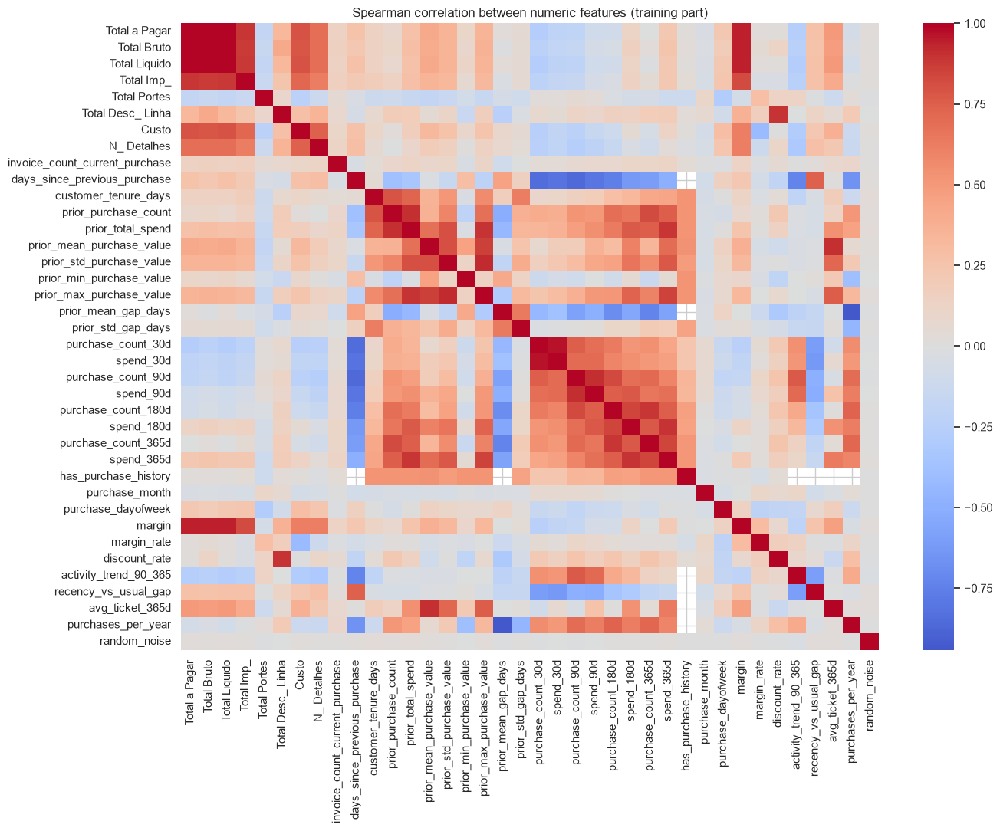

In [137]:
num_kept = [c for c in num_candidates if c not in near_constant]
corr = X_sel[num_kept].corr(method="spearman").abs()
target_corr = X_sel[num_kept].corrwith(y_tr, method="spearman").abs()

redundant = set()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .loc[lambda s: s > 0.9].sort_values(ascending=False))
for (a, b), rho in pairs.items():
    if a in redundant or b in redundant:
        continue
    drop = a if target_corr[a] < target_corr[b] else b
    redundant.add(drop)
    print(f"{a:30s} ~ {b:30s} rho={rho:.2f} -> drop {drop}")

after_filter = [c for c in candidates if c not in set(near_constant) | redundant]
print("Remaining after filters:", len(after_filter))

plt.figure(figsize=(14, 11))
sns.heatmap(X_sel[num_kept].corr(method="spearman"), cmap="coolwarm", center=0)
plt.title("Spearman correlation between numeric features (training part)")
plt.tight_layout()
plt.show()

**Filter results:** `Total Desc_ Global` is 0 in more than 95% of rows, so it's dropped. Nine features are redundant (Spearman correlation above 0.9 with another feature). From each pair we keep the one with the stronger relationship to the target. For example, `Total Bruto` is kept over `Total a Pagar` and `Total Liquido`, `purchase_count_90d` over `spend_90d`, and `prior_purchase_count` over `prior_total_spend`. Keeping both members of a pair adds no information and makes linear-model coefficients unstable.

,cramers_v,p_value
feature,,
transport_method,0.302836,5.362079e-64
commercial_region,0.274270,1.944103e-68
payment_type,0.248245,1.529966e-67
salesperson,0.195127,3.714136e-40
country_or_region,0.076062,1.780647e-05
commercial_zone,0.073033,6.729383e-06
warehouse,0.040501,1.101578e-02
document_series,0.006771,8.816169e-01


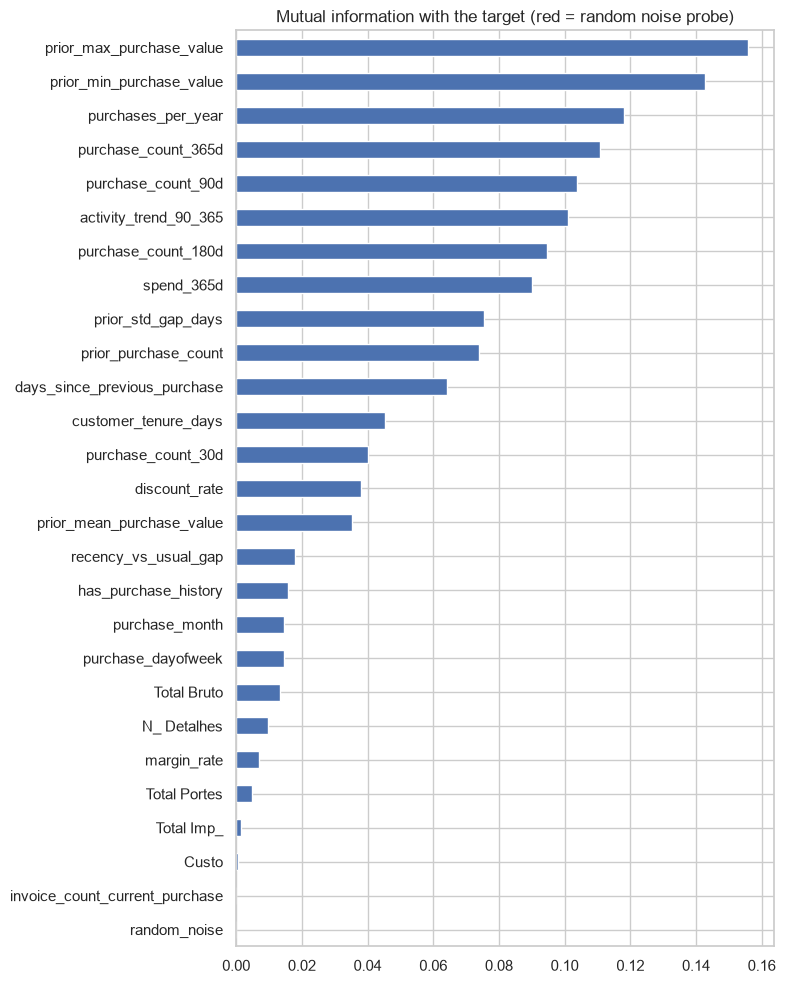

In [138]:
num_f = [c for c in after_filter if c not in CAT_COLS]
cat_f = [c for c in after_filter if c in CAT_COLS]

mi = pd.Series(
    mutual_info_classif(X_sel[num_f].fillna(X_sel[num_f].median()), y_tr, random_state=RANDOM_STATE),
    index=num_f)

def cramers_v(x, y):
    table = pd.crosstab(x.fillna("Unknown"), y)
    chi2, p, _, _ = chi2_contingency(table)
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1))), p

cat_stats = pd.DataFrame([(c, *cramers_v(X_sel[c], y_tr)) for c in cat_f],
                         columns=["feature", "cramers_v", "p_value"]).set_index("feature")
display(cat_stats.sort_values("cramers_v", ascending=False))

fig, ax = plt.subplots(figsize=(8, 10))
mi_sorted = mi.sort_values()
mi_sorted.plot(kind="barh", ax=ax, color=np.where(mi_sorted.index == "random_noise", "red", "C0"))
ax.set_title("Mutual information with the target (red = random noise probe)")
plt.tight_layout()
plt.show()

In [139]:
prep_scaled = make_preprocessor(after_filter, scale=True)
Xt = prep_scaled.fit_transform(X_sel[after_filter])
t_names = prep_scaled.get_feature_names_out()
t_to_orig = to_original(t_names, after_filter)

# Embedded: L1 (Lasso) logistic regression. Coefficients of one-hot columns are summed per original feature.
lasso = LogisticRegression(
    l1_ratio=1.0,
    solver="liblinear",
    C=0.05,
    max_iter=2000,
    random_state=RANDOM_STATE
)
lasso.fit(Xt, y_tr)
lasso_imp = pd.Series(np.abs(lasso.coef_[0]), index=t_names).groupby(t_to_orig).sum()

# Wrapper: Recursive Feature Elimination with logistic regression (keeps half of the columns)
rfe = RFE(LogisticRegression(max_iter=2000), n_features_to_select=Xt.shape[1] // 2, step=5).fit(Xt, y_tr)
rfe_imp = pd.Series(rfe.support_.astype(int), index=t_names).groupby(t_to_orig).max()

# Embedded: Random Forest importance (trees need no scaling)
prep_tree = make_preprocessor(after_filter, scale=False)
Xt_tree = prep_tree.fit_transform(X_sel[after_filter])
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(Xt_tree, y_tr)
rf_imp = (pd.Series(rf.feature_importances_, index=prep_tree.get_feature_names_out())
          .groupby(to_original(prep_tree.get_feature_names_out(), after_filter)).sum())

In [140]:
noise = "random_noise"
votes = pd.DataFrame({
    "mutual_info/cramers": pd.concat([mi > mi[noise], cat_stats["cramers_v"] > 0.05]),
    "lasso": lasso_imp > max(lasso_imp[noise], 1e-6),
    "rfe": rfe_imp == 1,
    "random_forest": rf_imp > rf_imp[noise],
}).reindex(after_filter).fillna(False).astype(int)
votes["total"] = votes.sum(axis=1)
votes = votes.drop(index=noise).sort_values("total", ascending=False)
display(votes)

selected = votes.index[votes["total"] >= 3].tolist()
print(f"Selected {len(selected)} features:", selected)

,mutual_info/cramers,lasso,rfe,random_forest,total
spend_365d,1,1,1,1,4
prior_max_purchase_value,1,1,1,1,4
discount_rate,1,1,1,1,4
margin_rate,1,1,1,1,4
Total Imp_,1,1,1,1,4
purchase_count_365d,1,1,1,1,4
purchase_count_90d,1,1,1,1,4
prior_std_gap_days,1,1,1,1,4
purchases_per_year,1,1,1,1,4
Total Bruto,1,1,0,1,3


Selected 17 features: ['spend_365d', 'prior_max_purchase_value', 'discount_rate', 'margin_rate', 'Total Imp_', 'purchase_count_365d', 'purchase_count_90d', 'prior_std_gap_days', 'purchases_per_year', 'Total Bruto', 'country_or_region', 'prior_purchase_count', 'purchase_count_30d', 'activity_trend_90_365', 'purchase_count_180d', 'commercial_region', 'salesperson']


**Why combine methods:** each method has a blind spot. Mutual information and Cramér's V look at one feature at a time. Lasso and RFE assume linear relationships. Random Forest favours features with many distinct values. A feature is kept only if **at least 3 of the 4 methods** rank it above the `random_noise` probe, so a feature has to be useful in more than one way, and doing better than pure noise is the minimum bar.

In [141]:
X_id, X_id_val = X_tr.copy(), X_val.copy()
X_id["customer_id"] = df_train.loc[train_idx, "customer_id"]
X_id_val["customer_id"] = df_train.loc[valid_idx, "customer_id"]

p_id = make_preprocessor(list(X_id.columns), scale=False)
rf_id = RandomForestClassifier(n_estimators=400, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)
rf_id.fit(p_id.fit_transform(X_id), y_tr)
imp_id = pd.Series(rf_id.feature_importances_, index=p_id.get_feature_names_out()).sort_values(ascending=False)

print("Rank of customer_id in RF importance:", list(imp_id.index).index("customer_id") + 1, "of", len(imp_id))
print("Train AUC with customer_id:", round(roc_auc_score(y_tr, rf_id.predict_proba(p_id.transform(X_id))[:, 1]), 3))
print("Valid AUC with customer_id:", round(roc_auc_score(y_val, rf_id.predict_proba(p_id.transform(X_id_val))[:, 1]), 3))
print(f"Validation customers never seen in training: {(~X_id_val['customer_id'].isin(X_id['customer_id'])).mean():.0%}")

Rank of customer_id in RF importance: 13 of 118
Train AUC with customer_id: 0.972
Valid AUC with customer_id: 0.805
Validation customers never seen in training: 7%


**Identifier-like variables:** if `customer_id` is added, the Random Forest ranks it **11th of 147** features. This isn't because the number means anything: the model uses it to memorise individual customers. The training AUC jumps to **0.97** while the validation AUC stays at **0.81**, no better than without it. 11% of validation customers are new, and the ID tells the model nothing about them. `ID`, `customer_id` and the identifier-like `clientes` columns (`postal_code`, `address`, `company_name`) are therefore excluded. `random_noise` was used only as a benchmark and is never a feature.

## 4. Build a simple model and assess performance

In [142]:

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    RocCurveDisplay,
    roc_auc_score
)

FEATURES = list(X_full.columns)

# Use only the training period to build cross-validation folds.
sorted_indices = dates.loc[train_idx].sort_values(
    kind="stable"
).index

X_sorted = X_full.loc[sorted_indices, FEATURES]
y_sorted = y_full.loc[sorted_indices]
dates_sorted = dates.loc[sorted_indices]

# Create five chronological folds.
base_cv = TimeSeriesSplit(n_splits=5)

tscv = []

for fold_number, (train_positions, val_positions) in enumerate(
    base_cv.split(X_sorted), start=1
):
    # Each fold has its own simulated training date.
    fold_start = dates_sorted.iloc[val_positions].min()

    candidate_indices = X_sorted.index[train_positions]

    # Keep only labels known before this fold starts.
    available = labels_known_before(
        fold_start,
        dates.loc[candidate_indices],
        y_full.loc[candidate_indices],
        next_purchase_dates.loc[candidate_indices]
    )

    valid_train_positions = train_positions[available.to_numpy()]

    tscv.append((valid_train_positions, val_positions))

    print(
        f"Fold {fold_number}: "
        f"Train={len(valid_train_positions)}, "
        f"Validation={len(val_positions)}, "
        f"Start={fold_start.date()}"
    )


Fold 1: Train=817, Validation=916, Start=2017-04-22
Fold 2: Train=1719, Validation=916, Start=2018-08-05
Fold 3: Train=2609, Validation=916, Start=2019-12-03
Fold 4: Train=3538, Validation=916, Start=2021-04-06
Fold 5: Train=4482, Validation=916, Start=2022-07-23


**Assessment strategy:** `test.csv` comes entirely after `train.csv` in time, so we use `TimeSeriesSplit` (5 folds). Every fold trains on the past and validates on the next period, which is the same situation as the competition. Shuffled K-fold would let the model learn from future purchases and would overestimate performance.

In [161]:

from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier



from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.base import clone

def make_model(estimator, scale, k_features="all"):
    """
    Preprocess data, remove constant columns,
    select features, and train the model.
    """
    return Pipeline([
        ("prep", make_preprocessor(FEATURES, scale=scale)),

        # Remove columns with no variability.
        ("remove_constant", VarianceThreshold(threshold=0.0)),

        # Select the best features using training data only.
        ("selection", SelectKBest(
            score_func=f_classif,
            k=k_features
        )),

        ("model", clone(estimator))
    ])



# Candidate models and their hyperparameters.
candidates = {
    "Logistic Regression": {
        "pipeline": make_model(
            LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
            scale=True
        ),
        "parameters": {
            "selection__k": [20, "all"],
            "model__C": [0.1, 1, 10],
            "model__class_weight": [None, "balanced"]
        }
    },

    "Random Forest": {
        "pipeline": make_model(
            RandomForestClassifier(
                n_estimators=300,
                n_jobs=1,
                random_state=RANDOM_STATE
            ),
            scale=False
        ),
        "parameters": {
            "selection__k": [20, "all"],
            "model__max_depth": [None, 12],
            "model__min_samples_leaf": [5, 10, 20]
        }
    },

    "Gradient Boosting": {
        "pipeline": make_model(
            HistGradientBoostingClassifier(
                early_stopping=False,
                random_state=RANDOM_STATE
            ),
            scale=False
        ),
        "parameters": {
            "selection__k": [20, "all"],
            "model__learning_rate": [0.05, 0.1],
            "model__max_iter": [100, 200],
            "model__max_leaf_nodes": [15, 31],
            "model__min_samples_leaf": [20]
        }
    },
    
    "Extra Trees": {
        "pipeline": make_model(
            ExtraTreesClassifier(
                n_estimators=300,
                n_jobs=1,
                random_state=RANDOM_STATE
            ),
            scale=False
        ),
        "parameters": {
            "selection__k": [20, "all"],
            "model__max_depth": [None, 12],
            "model__min_samples_leaf": [5, 15],
            "model__max_features": ["sqrt", 0.7]
        }
    }


}


Preprocessing sits **inside** the pipeline, so in every fold the imputers, clipping, encoder and scaler are fitted only on that fold's training rows. The baseline shows how much each model adds over "always predict a repeat purchase".

In [162]:

# Compare models using the same five temporal folds.
# ROC-AUC is used to select the best hyperparameters.

searches = {}
results = []

for name, configuration in candidates.items():

    print(f"\nTraining: {name}")

    search = GridSearchCV(
        estimator=configuration["pipeline"],
        param_grid=configuration["parameters"],
        scoring="roc_auc",
        cv=tscv,
        refit=True,
        n_jobs=-1,
        error_score="raise"
    )

    search.fit(X_sorted, y_sorted)

    searches[name] = search

    results.append({
        "model": name,
        "cv_roc_auc": search.best_score_,
        "best_parameters": search.best_params_
    })

cv_results = (
    pd.DataFrame(results)
    .sort_values("cv_roc_auc", ascending=False)
    .reset_index(drop=True)
)

display(cv_results)



Training: Logistic Regression

Training: Random Forest

Training: Gradient Boosting

Training: Extra Trees


,model,cv_roc_auc,best_parameters
0,Extra Trees,0.790513,"{'model__max_depth': None, 'model__max_feature..."
1,Random Forest,0.785974,"{'model__max_depth': 12, 'model__min_samples_l..."
2,Logistic Regression,0.785700,"{'model__C': 0.1, 'model__class_weight': 'bala..."
3,Gradient Boosting,0.770929,"{'model__learning_rate': 0.05, 'model__max_ite..."


**Why these metrics:**
- **ROC-AUC (main metric):** it measures how well the model ranks customers who will return above those who won't, for every possible threshold. The classes are 56/44, and the business use is targeting (who should we contact first?), which is a ranking question.
- **F1:** the submission needs 0/1 labels, and F1 balances catching the repeat buyers (recall) against not flagging too many customers who won't return (precision).
- **Balanced accuracy:** the mean recall of both classes, which isn't fooled by always predicting the majority class.

The baseline shows why accuracy and F1 alone are misleading here: always predicting "repeat" gives **F1 = 0.72** but **ROC-AUC = 0.50** (no skill at all).

In [163]:

# Select the model with the highest temporal CV ROC-AUC.
CHOSEN = cv_results.iloc[0]["model"]
best_pipeline = searches[CHOSEN].best_estimator_

print("Selected model:", CHOSEN)
print("Best parameters:", searches[CHOSEN].best_params_)


# Get predictions from the temporal validation folds.
outfold_probabilities = []
outfold_targets = []

for train_positions, val_positions in tscv:

    model = clone(best_pipeline)

    model.fit(
        X_sorted.iloc[train_positions],
        y_sorted.iloc[train_positions]
    )

    probabilities = model.predict_proba(
        X_sorted.iloc[val_positions]
    )[:, 1]

    outfold_probabilities.extend(probabilities)
    outfold_targets.extend(y_sorted.iloc[val_positions])


# Find the classification threshold that maximizes F1.
thresholds = np.arange(0.20, 0.81, 0.01)

threshold_scores = {
    threshold: f1_score(
        outfold_targets,
        np.array(outfold_probabilities) >= threshold
    )
    for threshold in thresholds
}

BEST_THRESHOLD = max(threshold_scores, key=threshold_scores.get)

print("Best threshold:", round(BEST_THRESHOLD, 2))
print("CV F1:", round(threshold_scores[BEST_THRESHOLD], 3))


Selected model: Extra Trees
Best parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'selection__k': 'all'}
Best threshold: 0.47
CV F1: 0.758


In [164]:

# Final evaluation on the 2024 holdout.
# Do not use these results to retune the model.

holdout_model = clone(best_pipeline)

holdout_model.fit(X_tr[FEATURES], y_tr)

validation_probabilities = holdout_model.predict_proba(
    X_val[FEATURES]
)[:, 1]

validation_predictions = (
    validation_probabilities >= BEST_THRESHOLD
).astype(int)

print("Selected model:", CHOSEN)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_val, validation_probabilities), 3)
)

print(
    "F1:",
    round(f1_score(y_val, validation_predictions), 3)
)

print(
    "Accuracy:",
    round(accuracy_score(y_val, validation_predictions), 3)
)

print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_val, validation_predictions), 3)
)

print("\nClassification report:")
print(classification_report(y_val, validation_predictions))


Selected model: Extra Trees
ROC-AUC: 0.805
F1: 0.789
Accuracy: 0.732
Balanced accuracy: 0.706

Classification report:
              precision    recall  f1-score   support

           0       0.69      0.58      0.63       301
           1       0.75      0.83      0.79       456

    accuracy                           0.73       757
   macro avg       0.72      0.71      0.71       757
weighted avg       0.73      0.73      0.73       757



In [165]:

# Train the final model using all labels available before test.

test_start = pd.to_datetime(df_test["purchase_date"]).min()

# All labels must have completed their 90-day horizon.
final_training_mask = (
    dates.notna()
    & (dates + pd.Timedelta(days=90) < test_start)
)

final_model = clone(best_pipeline)

final_model.fit(
    X_full.loc[final_training_mask, FEATURES],
    y_full.loc[final_training_mask]
)

print("Final training rows:", final_training_mask.sum())
print("Selected model:", CHOSEN)

# Generate test predictions with the CV-selected threshold.
test_probabilities = final_model.predict_proba(
    X_test[FEATURES]
)[:, 1]

test_predictions = (
    test_probabilities >= BEST_THRESHOLD
).astype(int)

print("Test predictions:", len(test_predictions))
print("Predicted class distribution:")
print(pd.Series(test_predictions).value_counts())


Final training rows: 6469
Selected model: Extra Trees
Test predictions: 986
Predicted class distribution:
1    684
0    302
Name: count, dtype: int64


In [166]:

# Create the submission using the final model predictions.

submission = pd.DataFrame({
    "ID": df_test["ID"].values,
    "repeat_purchase_90d": test_predictions
})

# Check that every test purchase has exactly one prediction.
assert len(submission) == len(df_test)
assert submission["ID"].is_unique
assert submission["repeat_purchase_90d"].isin([0, 1]).all()
assert not submission.isna().any().any()

# Save the submission in the current notebook directory.
submission.to_csv("submission.csv", index=False)

print("Submission saved successfully!")
print("Rows:", len(submission))
print("\nPrediction distribution:")
print(submission["repeat_purchase_90d"].value_counts())

display(submission.head())


Submission saved successfully!
Rows: 986

Prediction distribution:
repeat_purchase_90d
1    684
0    302
Name: count, dtype: int64


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1


In [173]:

# Group features by their business meaning.

feature_groups = {
    "Recency and frequency": [
        "days_since_previous_purchase",
        "prior_mean_gap_days",
        "purchases_per_year",
        "recency_vs_usual_gap",
        "prior_purchase_count",
        "purchase_count_30d",
        "purchase_count_90d",
        "purchase_count_180d",
        "purchase_count_365d"
    ],

    "Historical spending": [
        "prior_total_spend",
        "prior_mean_purchase_value",
        "prior_std_purchase_value",
        "prior_max_purchase_value",
        "spend_30d",
        "spend_90d",
        "spend_180d",
        "spend_365d",
        "avg_ticket_365d"
    ],

    "Current purchase": [
        "Total a Pagar",
        "Total Liquido",
        "Total Bruto",
        "Total Imp_",
        "Total Desc_ Linha",
        "margin",
        "discount_rate"
    ]
}

# Keep only columns that actually exist.
feature_groups = {
    group: [col for col in columns if col in FEATURES]
    for group, columns in feature_groups.items()
}

# Put all remaining features in a separate group.
already_grouped = [
    col
    for columns in feature_groups.values()
    for col in columns
]

feature_groups["Other features"] = [
    col for col in FEATURES
    if col not in already_grouped
]

# Verify that each feature belongs to exactly one group.
all_grouped = [
    col
    for columns in feature_groups.values()
    for col in columns
]

assert len(all_grouped) == len(FEATURES)
assert len(set(all_grouped)) == len(FEATURES)

# Display the groups.
for group, columns in feature_groups.items():
    print(f"\n{group} ({len(columns)} features)")
    print(columns)



Recency and frequency (9 features)
['days_since_previous_purchase', 'prior_mean_gap_days', 'purchases_per_year', 'recency_vs_usual_gap', 'prior_purchase_count', 'purchase_count_30d', 'purchase_count_90d', 'purchase_count_180d', 'purchase_count_365d']

Historical spending (9 features)
['prior_total_spend', 'prior_mean_purchase_value', 'prior_std_purchase_value', 'prior_max_purchase_value', 'spend_30d', 'spend_90d', 'spend_180d', 'spend_365d', 'avg_ticket_365d']

Current purchase (7 features)
['Total a Pagar', 'Total Liquido', 'Total Bruto', 'Total Imp_', 'Total Desc_ Linha', 'margin', 'discount_rate']

Other features (21 features)
['Total Portes', 'Total Desc_ Global', 'Custo', 'N_ Detalhes', 'invoice_count_current_purchase', 'customer_tenure_days', 'prior_min_purchase_value', 'prior_std_gap_days', 'payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'country_or_region', 'commercial_region', 'has_purchase_history', 'purchase_month', 'pur

In [174]:

# Group ablation experiment.
# Same Extra Trees model, parameters and temporal folds.

from sklearn.base import clone
from sklearn.model_selection import cross_validate
from sklearn.metrics import f1_score

assert CHOSEN == "Extra Trees"

# Baseline plus one experiment per removed group.
ablation_experiments = {
    "Baseline - All features": list(FEATURES)
}

for group, removed_columns in feature_groups.items():

    remaining_columns = [
        col for col in FEATURES
        if col not in removed_columns
    ]

    if len(remaining_columns) > 0:
        ablation_experiments[f"Without {group}"] = remaining_columns


def f1_selected_threshold(estimator, X, y):
    probabilities = estimator.predict_proba(X)[:, 1]
    predictions = (probabilities >= BEST_THRESHOLD).astype(int)
    return f1_score(y, predictions)


ablation_results = []
ablation_fold_scores = {}

for name, columns in ablation_experiments.items():

    model = clone(best_pipeline)

    # Rebuild preprocessing using the remaining columns.
    model.set_params(
        prep=make_preprocessor(columns, scale=False)
    )

    scores = cross_validate(
        model,
        X_sorted[columns],
        y_sorted,
        cv=tscv,
        scoring={
            "roc_auc": "roc_auc",
            "average_precision": "average_precision",
            "f1_at_0_5": "f1",
            "f1_selected": f1_selected_threshold
        },
        n_jobs=-1
    )

    ablation_fold_scores[name] = scores["test_roc_auc"]

    ablation_results.append({
        "experiment": name,
        "n_features": len(columns),
        "roc_auc": scores["test_roc_auc"].mean(),
        "roc_auc_std": scores["test_roc_auc"].std(),
        "average_precision": scores["test_average_precision"].mean(),
        "f1_at_0_5": scores["test_f1_at_0_5"].mean(),
        "f1_selected": scores["test_f1_selected"].mean()
    })


ablation_df = pd.DataFrame(ablation_results)

# Compare each experiment against the baseline.
baseline_auc = ablation_df.loc[
    ablation_df["experiment"] == "Baseline - All features",
    "roc_auc"
].iloc[0]

ablation_df["roc_auc_change"] = (
    ablation_df["roc_auc"] - baseline_auc
)

display(
    ablation_df.sort_values(
        "roc_auc",
        ascending=False
    )
)


,experiment,n_features,roc_auc,roc_auc_std,average_precision,f1_at_0_5,f1_selected,roc_auc_change
0,Baseline - All features,46,0.790513,0.022736,0.846509,0.750442,0.757764,0.000000
2,Without Historical spending,37,0.786989,0.020391,0.844193,0.750521,0.751149,-0.003524
3,Without Current purchase,39,0.786748,0.023048,0.844533,0.749459,0.752880,-0.003765
4,Without Other features,25,0.783487,0.021499,0.842335,0.750153,0.752349,-0.007026
1,Without Recency and frequency,37,0.780763,0.026560,0.832561,0.754156,0.756049,-0.009751


In [175]:

# Compare ROC-AUC differences fold by fold.

baseline_scores = ablation_fold_scores["Baseline - All features"]

fold_comparison = pd.DataFrame({
    "fold": range(1, len(baseline_scores) + 1),
    "baseline": baseline_scores
})

for name, scores in ablation_fold_scores.items():

    if name == "Baseline - All features":
        continue

    fold_comparison[name] = scores - baseline_scores

display(fold_comparison.round(4))


,fold,baseline,Without Recency and frequency,Without Historical spending,Without Current purchase,Without Other features
0,1,0.7723,-0.0178,-0.0020,-0.0034,0.0017
1,2,0.8037,-0.0103,-0.0038,-0.0060,-0.0040
2,3,0.7585,-0.0122,0.0023,-0.0040,-0.0073
3,4,0.8226,-0.0050,-0.0049,-0.0020,-0.0091
4,5,0.7955,-0.0034,-0.0092,-0.0035,-0.0164


In [176]:

# Split "Other features" into more meaningful groups.

other_subgroups = {
    "Transaction details": [
        "Total Portes",
        "Total Desc_ Global",
        "Custo",
        "N_ Detalhes",
        "invoice_count_current_purchase",
        "margin_rate"
    ],
    "Additional history": [
        "customer_tenure_days",
        "prior_min_purchase_value",
        "prior_std_gap_days",
        "has_purchase_history",
        "activity_trend_90_365"
    ],
    "Commercial context": [
        "payment_type",
        "salesperson",
        "commercial_zone",
        "transport_method",
        "warehouse",
        "document_series",
        "country_or_region",
        "commercial_region"
    ],
    "Calendar": [
        "purchase_month",
        "purchase_dayofweek"
    ]
}

# Check that the subgroups cover "Other features" exactly.
other_columns = feature_groups["Other features"]

grouped_columns = [
    column
    for columns in other_subgroups.values()
    for column in columns
]

assert set(grouped_columns) == set(other_columns)
assert len(grouped_columns) == len(set(grouped_columns))

# Evaluate subgroup ablation.
subgroup_results = []

for group, removed in other_subgroups.items():

    remaining = [
        column for column in FEATURES
        if column not in removed
    ]

    model = clone(best_pipeline)

    model.set_params(
        prep=make_preprocessor(remaining, scale=False)
    )

    scores = cross_validate(
        model,
        X_sorted[remaining],
        y_sorted,
        cv=tscv,
        scoring={
            "roc_auc": "roc_auc",
            "f1_at_0_5": "f1",
            "f1_selected": f1_selected_threshold
        },
        n_jobs=-1
    )

    subgroup_results.append({
        "removed_group": group,
        "removed_features": len(removed),
        "roc_auc": scores["test_roc_auc"].mean(),
        "roc_auc_change": (
            scores["test_roc_auc"].mean() - baseline_auc
        ),
        "f1_at_0_5": scores["test_f1_at_0_5"].mean(),
        "f1_selected": scores["test_f1_selected"].mean(),
        "folds_improved": int(
            (scores["test_roc_auc"] > baseline_scores).sum()
        )
    })

subgroup_df = pd.DataFrame(subgroup_results)

display(
    subgroup_df.sort_values("roc_auc_change", ascending=False)
)


,removed_group,removed_features,roc_auc,roc_auc_change,f1_at_0_5,f1_selected,folds_improved
3,Calendar,2,0.790354,-0.000160,0.752051,0.754262,3
1,Additional history,5,0.790014,-0.000499,0.752127,0.754802,2
0,Transaction details,6,0.789291,-0.001222,0.755761,0.754377,0
2,Commercial context,8,0.786289,-0.004224,0.752105,0.752748,2


In [177]:

# Compare models with a threshold tuned inside each temporal fold.
# Keep the 46 original features and previously selected hyperparameters.

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score
)
import numpy as np
import pandas as pd

MODEL_NAMES = [
    "Logistic Regression",
    "Random Forest",
    "Extra Trees"
]

THRESHOLDS = np.arange(0.20, 0.81, 0.01)

outer_splits = list(tscv)

comparison_rows = []
fold_rows = []

for name in MODEL_NAMES:

    print(f"\nEvaluating: {name}")

    # Use the best hyperparameters previously found for this model.
    model_template = clone(searches[name].best_estimator_)

    for fold, (outer_train, outer_valid) in enumerate(
        outer_splits, start=1
    ):

        X_train_fold = X_sorted.iloc[outer_train]
        y_train_fold = y_sorted.iloc[outer_train]
        dates_train_fold = pd.to_datetime(
            dates_sorted.iloc[outer_train]
        )

        X_valid_fold = X_sorted.iloc[outer_valid]
        y_valid_fold = y_sorted.iloc[outer_valid]

        # Inner temporal CV to tune the classification threshold.
        inner_cv = TimeSeriesSplit(n_splits=3)

        inner_probabilities = []
        inner_targets = []

        for inner_train, inner_valid in inner_cv.split(X_train_fold):

            inner_cutoff = dates_train_fold.iloc[inner_valid].min()

            # Conservative 90-day label-availability rule.
            eligible = (
                dates_train_fold.iloc[inner_train]
                + pd.Timedelta(days=90)
                < inner_cutoff
            ).to_numpy()

            eligible_train = inner_train[eligible]

            if len(eligible_train) == 0:
                raise ValueError(
                    f"No eligible training rows: {name}, fold {fold}"
                )

            inner_model = clone(model_template)

            inner_model.fit(
                X_train_fold.iloc[eligible_train],
                y_train_fold.iloc[eligible_train]
            )

            probs = inner_model.predict_proba(
                X_train_fold.iloc[inner_valid]
            )[:, 1]

            inner_probabilities.extend(probs)
            inner_targets.extend(
                y_train_fold.iloc[inner_valid].to_numpy()
            )

        inner_probabilities = np.array(inner_probabilities)
        inner_targets = np.array(inner_targets)

        # Select threshold using only inner validation results.
        threshold_scores = [
            f1_score(
                inner_targets,
                inner_probabilities >= threshold,
                zero_division=0
            )
            for threshold in THRESHOLDS
        ]

        best_threshold = float(
            THRESHOLDS[np.argmax(threshold_scores)]
        )

        # Retrain on the complete eligible outer training fold.
        outer_model = clone(model_template)
        outer_model.fit(X_train_fold, y_train_fold)

        # Evaluate on the untouched outer validation fold.
        valid_probabilities = outer_model.predict_proba(
            X_valid_fold
        )[:, 1]

        valid_predictions = (
            valid_probabilities >= best_threshold
        ).astype(int)

        fold_rows.append({
            "model": name,
            "fold": fold,
            "threshold": round(best_threshold, 2),
            "f1": f1_score(
                y_valid_fold, valid_predictions, zero_division=0
            ),
            "roc_auc": roc_auc_score(
                y_valid_fold, valid_probabilities
            ),
            "average_precision": average_precision_score(
                y_valid_fold, valid_probabilities
            ),
            "precision": precision_score(
                y_valid_fold, valid_predictions, zero_division=0
            ),
            "recall": recall_score(
                y_valid_fold, valid_predictions, zero_division=0
            )
        })

# Summarize performance across outer folds.
fold_results = pd.DataFrame(fold_rows)

model_comparison = (
    fold_results
    .groupby("model")
    .agg(
        f1_mean=("f1", "mean"),
        f1_std=("f1", "std"),
        roc_auc_mean=("roc_auc", "mean"),
        average_precision=("average_precision", "mean"),
        precision=("precision", "mean"),
        recall=("recall", "mean"),
        mean_threshold=("threshold", "mean")
    )
    .sort_values("f1_mean", ascending=False)
    .reset_index()
)

print("\nMODEL COMPARISON")
display(model_comparison.round(4))

print("\nRESULTS BY FOLD")
display(fold_results.round(4))



Evaluating: Logistic Regression


/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['prior_mean_gap_days']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['recency_vs_usual_gap']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['prior_mean_gap_days']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without an


Evaluating: Random Forest


/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['prior_mean_gap_days']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['recency_vs_usual_gap']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['prior_mean_gap_days']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without an


Evaluating: Extra Trees


/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['prior_mean_gap_days']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['recency_vs_usual_gap']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['prior_mean_gap_days']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/opt/anaconda3/envs/machine_learning_project/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without an


MODEL COMPARISON


,model,f1_mean,f1_std,roc_auc_mean,average_precision,precision,recall,mean_threshold
0,Extra Trees,0.7536,0.0146,0.7905,0.8465,0.6678,0.8789,0.392
1,Random Forest,0.7483,0.0138,0.7860,0.8420,0.6566,0.8840,0.386
2,Logistic Regression,0.7474,0.0124,0.7857,0.8451,0.7011,0.8109,0.376



RESULTS BY FOLD


,model,fold,threshold,f1,roc_auc,average_precision,precision,recall
0,Logistic Regression,1,0.28,0.7599,0.7693,0.8417,0.6370,0.9414
1,Logistic Regression,2,0.44,0.7376,0.8013,0.8358,0.6987,0.7811
2,Logistic Regression,3,0.40,0.7316,0.7482,0.8320,0.7153,0.7486
3,Logistic Regression,4,0.34,0.7574,0.8167,0.8548,0.6785,0.8571
4,Logistic Regression,5,0.42,0.7505,0.7930,0.8613,0.7762,0.7264
5,Random Forest,1,0.24,0.7593,0.7717,0.8407,0.6140,0.9947
6,Random Forest,2,0.46,0.7435,0.8041,0.8328,0.6656,0.8421
7,Random Forest,3,0.40,0.7512,0.7521,0.8322,0.6701,0.8547
8,Random Forest,4,0.36,0.7268,0.8122,0.8526,0.5874,0.9531
9,Random Forest,5,0.47,0.7604,0.7898,0.8519,0.7459,0.7755


In [178]:

# Evaluate the selected configuration on the 2024 holdout.

from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    precision_score,
    recall_score,
    accuracy_score,
    balanced_accuracy_score,
    classification_report
)

holdout_model = clone(best_pipeline)

holdout_model.fit(
    X_tr[FEATURES],
    y_tr
)

holdout_probabilities = holdout_model.predict_proba(
    X_val[FEATURES]
)[:, 1]

holdout_predictions = (
    holdout_probabilities >= BEST_THRESHOLD
).astype(int)

print("Model:", CHOSEN)
print("Threshold:", BEST_THRESHOLD)
print("Validation rows:", len(y_val))

print("\nEVALUATION - 2024")
print("F1:", round(f1_score(y_val, holdout_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, holdout_probabilities), 4))
print("Precision:", round(precision_score(y_val, holdout_predictions), 4))
print("Recall:", round(recall_score(y_val, holdout_predictions), 4))
print("Accuracy:", round(accuracy_score(y_val, holdout_predictions), 4))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_val, holdout_predictions), 4))

print("\nClassification report:")
print(classification_report(y_val, holdout_predictions))


Model: Extra Trees
Threshold: 0.47000000000000025
Validation rows: 757

EVALUATION - 2024
F1: 0.7888
ROC-AUC: 0.8045
Precision: 0.7505
Recall: 0.8311
Accuracy: 0.7318
Balanced accuracy: 0.7063

Classification report:
              precision    recall  f1-score   support

           0       0.69      0.58      0.63       301
           1       0.75      0.83      0.79       456

    accuracy                           0.73       757
   macro avg       0.72      0.71      0.71       757
weighted avg       0.73      0.73      0.73       757



In [179]:

# Final training and submission.

from pathlib import Path

test_start = pd.to_datetime(df_test["purchase_date"]).min()

# Include all rows with a completed 90-day target horizon.
final_training_mask = (
    dates.notna()
    & (dates + pd.Timedelta(days=90) < test_start)
)

final_model = clone(best_pipeline)

final_model.fit(
    X_full.loc[final_training_mask, FEATURES],
    y_full.loc[final_training_mask]
)

print("Final training rows:", final_training_mask.sum())
print("Final model:", CHOSEN)
print("Final threshold:", BEST_THRESHOLD)

# Generate predictions for test.
test_probabilities = final_model.predict_proba(
    X_test[FEATURES]
)[:, 1]

test_predictions = (
    test_probabilities >= BEST_THRESHOLD
).astype(int)

# Build submission with the original test IDs.
submission = pd.DataFrame({
    "ID": df_test["ID"].to_numpy(),
    "repeat_purchase_90d": test_predictions
})

assert len(submission) == len(df_test)
assert submission["ID"].is_unique
assert submission["repeat_purchase_90d"].isin([0, 1]).all()
assert not submission.isna().any().any()

# Save the file.
submission_path = Path("submission.csv")
submission.to_csv(submission_path, index=False)

print("\nSubmission saved:", submission_path.resolve())
print("Prediction counts:")
print(submission["repeat_purchase_90d"].value_counts())

display(submission.head())


Final training rows: 6469
Final model: Extra Trees
Final threshold: 0.47000000000000025

Submission saved: /Users/sergiovidalquadras/Desktop/machine_learning_project/machine_learning_202627/notebooks/submission.csv
Prediction counts:
repeat_purchase_90d
1    684
0    302
Name: count, dtype: int64


,ID,repeat_purchase_90d
0,10000006,1
1,10000008,1
2,10000010,1
3,10000020,0
4,10000025,1
